#  EXPLORATORY DATA ANALYSIS

Målet med prosjektet er å forutsi om **hvit vinner** et sjakkparti, bare basert på informasjon som er kjent før partiet starter: ratingen til spillerne, tidskontrollen, åpningen og tidspunktet.

Datasettet er 20 000 tilfeldige partier fra Lichess (juni 2013). Hvordan datasettet ble laget, ligger i `data_prep.ipynb`.

In [1]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

In [2]:
# Vi laster inn datasettet og undersøker det for å se hva vi har å jobbe med.
c_dataframe = pd.read_csv('../dataset/chess_games.csv')
print(f"{c_dataframe.shape[0]} rows, {c_dataframe.shape[1]} columns")

20000 rows, 15 columns


In [3]:
# Ser de første 20 radene i datasettet for å få en oversikt over dataene.
c_dataframe.head(20)

,game_type,time_control,base_time,increment,hour,white_elo,black_elo,eco,opening,opening_family,num_moves,termination,white_rating_change,black_rating_change,result
0,Bullet,60+0,60.0,0.0,23,1624.0,1471.0,B06,Modern Defense,Modern Defense,40,Time forfeit,7.0,-6.0,1-0
1,Blitz,180+2,180.0,2.0,20,1742.0,1797.0,B12,Caro-Kann Defense: Advance Variation,Caro-Kann Defense,43,Normal,-23.0,9.0,0-1
2,Bullet,60+1,60.0,1.0,12,1558.0,1934.0,D00,Queen's Pawn Game #2,Queen's Pawn Game,75,Time forfeit,-3.0,4.0,0-1
3,Blitz,120+2,120.0,2.0,10,1553.0,1461.0,B00,"Nimzowitsch Defense, Declined Variation","Nimzowitsch Defense, Declined Variation",47,Normal,9.0,-8.0,1-0
4,Classical,900+8,900.0,8.0,23,1360.0,1419.0,B20,Sicilian Defense,Sicilian Defense,35,Normal,14.0,-12.0,1-0
5,Blitz,240+0,240.0,0.0,17,1810.0,1741.0,C41,Philidor Defense: Exchange Variation,Philidor Defense,62,Time forfeit,17.0,-10.0,1-0
6,Classical,300+5,300.0,5.0,1,1639.0,1638.0,A43,Old Benoni Defense,Old Benoni Defense,24,Normal,-17.0,38.0,0-1
7,Bullet,60+0,60.0,0.0,8,1781.0,1829.0,B40,Sicilian Defense: Delayed Alapin Variation,Sicilian Defense,58,Normal,1.0,-1.0,1/2-1/2
8,Classical,1200+0,1200.0,0.0,7,1371.0,1517.0,B01,Scandinavian Defense,Scandinavian Defense,8,Normal,-7.0,7.0,0-1
9,Blitz,180+0,180.0,0.0,21,1589.0,1373.0,B06,Robatsch (Modern) Defense,Robatsch (Modern) Defense,24,Time forfeit,39.0,-5.0,1-0


In [4]:
print(f"Duplicate rows: {c_dataframe.duplicated().sum()}")

Duplicate rows: 0


In [5]:
# Deler kolonnene inn i kategoriske og numeriske, samme måte som i forrige prosjekt.
# select_dtypes er tryggere enn å sjekke dtype == 'string' for hver kolonne.

cat_col = c_dataframe.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
num_col = c_dataframe.select_dtypes(include=['number']).columns.tolist()

print(f"\nCategorical Columns: {cat_col}")
print(f"\nNumerical Columns: {num_col}")


Categorical Columns: ['game_type', 'time_control', 'eco', 'opening', 'opening_family', 'termination', 'result']

Numerical Columns: ['base_time', 'increment', 'hour', 'white_elo', 'black_elo', 'num_moves', 'white_rating_change', 'black_rating_change']


In [6]:
# Sjekker hvor mange unike verdier som finnes i hver kategoriske kolonne
c_dataframe[cat_col].nunique()

game_type            4
time_control       315
eco                337
opening           1309
opening_family     199
termination          2
result               3
dtype: int64

#### Results :
`game_type` har 4 kategorier og `termination` bare 2, så de er enkle å jobbe med. `result` har 3 verdier: hvit vinner (1-0), svart vinner (0-1) og remis (1/2-1/2).

Resten har veldig mange kategorier: `opening` har 1309 forskjellige åpninger, `eco` har 337 koder og `time_control` har 315 kombinasjoner. Det er altfor mange til å bruke direkte i en modell, så disse må forenkles senere. `opening_family` (199) er allerede en forenkling som jeg laget i data_prep, men det er fortsatt mange.

In [7]:
# Sjekker for manglende verdier i datasettet
c_dataframe.isnull().sum()

game_type               0
time_control            0
base_time              45
increment              45
hour                    0
white_elo              21
black_elo              20
eco                     0
opening                 0
opening_family          0
num_moves               0
termination             0
white_rating_change    41
black_rating_change    41
result                  0
dtype: int64

In [8]:
# Samme som over, men i prosent av hele datasettet
round((c_dataframe.isnull().sum() / c_dataframe.shape[0]) * 100, 2)

game_type              0.00
time_control           0.00
base_time              0.22
increment              0.22
hour                   0.00
white_elo              0.10
black_elo              0.10
eco                    0.00
opening                0.00
opening_family         0.00
num_moves              0.00
termination            0.00
white_rating_change    0.20
black_rating_change    0.20
result                 0.00
dtype: float64

In [9]:
# Hvilke partier mangler base_time? Min mistanke er at det er correspondence-partiene,
# siden de ikke har klokke ("-" i time_control).
c_dataframe[c_dataframe['base_time'].isnull()]['game_type'].value_counts()

game_type
Correspondence    45
Name: count, dtype: int64

#### Results :
Det mangler veldig lite data i dette datasettet:

- `base_time` og `increment` mangler i 45 partier (0,22 %). Som jeg trodde, er dette akkurat de 45 correspondence-partiene, fordi de ikke har klokke.
- `white_elo` og `black_elo` mangler i rundt 20 partier hver (0,10 %).
- `white_rating_change` og `black_rating_change` mangler i 41 partier (0,20 %).

Det er så få partier at det er greit å fjerne dem senere, i stedet for å fylle inn verdier. Spesielt ratingen vil jeg ikke gjette på, siden jeg tror det er den viktigste informasjonen vi har.

In [10]:
c_dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   game_type            20000 non-null  str    
 1   time_control         20000 non-null  str    
 2   base_time            19955 non-null  float64
 3   increment            19955 non-null  float64
 4   hour                 20000 non-null  int64  
 5   white_elo            19979 non-null  float64
 6   black_elo            19980 non-null  float64
 7   eco                  20000 non-null  str    
 8   opening              20000 non-null  str    
 9   opening_family       20000 non-null  str    
 10  num_moves            20000 non-null  int64  
 11  termination          20000 non-null  str    
 12  white_rating_change  19959 non-null  float64
 13  black_rating_change  19959 non-null  float64
 14  result               20000 non-null  str    
dtypes: float64(6), int64(2), str(7)
memory usage: 3

In [11]:
# Sjekker mattematisk beskrivelse av datasettet for å få en oversikt over statistikken til de numeriske kolonnene.
c_dataframe.describe()

,base_time,increment,hour,white_elo,black_elo,num_moves,white_rating_change,black_rating_change
count,19955.000000,19955.000000,20000.000000,19979.000000,19980.000000,20000.000000,19959.000000,19959.000000
mean,317.905287,2.667953,13.484500,1604.946444,1594.881832,33.903300,0.772935,-2.262488
std,296.439704,4.352029,6.144977,209.483288,217.230910,16.437441,37.877080,42.639869
min,0.000000,0.000000,0.000000,796.000000,786.000000,1.000000,-412.000000,-472.000000
25%,120.000000,0.000000,9.000000,1464.500000,1453.000000,23.000000,-10.000000,-11.000000
50%,300.000000,0.000000,14.000000,1600.000000,1586.000000,32.000000,3.000000,-3.000000
75%,360.000000,4.000000,18.000000,1743.000000,1740.000000,43.000000,10.000000,10.000000
max,1800.000000,30.000000,23.000000,2294.000000,2338.000000,146.000000,480.000000,597.000000


De fleste intervallene ser realistiske ut:

"white_elo" / "black_elo": 786–2338, med gjennomsnitt rundt 1600. Lichess gir nye spillere 1500 i rating, så det passer at de fleste ligger rundt der.

"base_time": 0–1800 sekunder. 0 ser rart ut, men det er partier som "0+1", hvor man bare får 1 sekund ekstra per trekk. Det er altså ikke en feil.

"increment": 0–30 sekunder per trekk. Medianen er 0, så de fleste partiene har ingen ekstra tid per trekk.

"num_moves": 1–146 trekk, gjennomsnitt ca. 34. Partier på 1 trekk er sannsynligvis noen som ga opp eller forlot partiet med en gang.

"white_rating_change": −412 til +480. De fleste endringene er små (25–75 % ligger mellom −10 og +10), men noen er veldig store. Det kan skje når nye spillere med usikker rating spiller sine første partier.

In [12]:
# Mer detaljert oversikt over de kategoriske kolonnene som ikke har altfor mange kategorier
small_cat_cols = ['game_type', 'termination', 'result']

for col in small_cat_cols:
    print(f"{col}:")
    print(c_dataframe[col].value_counts())
    print("\n")

game_type:
game_type
Blitz             7920
Classical         6951
Bullet            5084
Correspondence      45
Name: count, dtype: int64


termination:
termination
Normal          13815
Time forfeit     6185
Name: count, dtype: int64


result:
result
1-0        10324
0-1         9004
1/2-1/2      672
Name: count, dtype: int64




#### Game type:
Blitz (7920) og Classical (6951) er de vanligste, fulgt av Bullet (5084). Correspondence har bare 45 partier, så den kategorien er for liten til at en modell kan lære noe av den.

#### Termination:
13 815 partier endte normalt (sjakkmatt, oppgitt eller remis), mens 6185 endte fordi en spiller gikk tom for tid. Det er nesten en tredjedel, noe som viser hvor mye klokka betyr på Lichess.

#### Result:
Hvit vinner 10 324 partier, svart vinner 9004 og bare 672 ender remis. Hvit vinner altså litt oftere enn svart. Det passer med at hvit har en liten fordel i sjakk, siden hvit alltid starter.

In [13]:
# De 15 vanligste åpningsfamiliene
c_dataframe['opening_family'].value_counts().head(15)

opening_family
Sicilian Defense           2071
French Defense             1528
Queen's Pawn Game          1342
King's Pawn Game            966
Scandinavian Defense        883
Philidor Defense            745
Caro-Kann Defense           663
Italian Game                657
English Opening             570
Van't Kruijs Opening        493
Bishop's Opening            487
Modern Defense              470
Ruy Lopez                   449
Horwitz Defense             384
Queen's Gambit Declined     382
Name: count, dtype: int64

In [14]:
# Hvor mange partier dekker de 10 vanligste åpningsfamiliene til sammen?
top10_share = c_dataframe['opening_family'].value_counts().head(10).sum() / len(c_dataframe)
print(f"De 10 vanligste åpningsfamiliene dekker {top10_share*100:.1f}% av partiene")

De 10 vanligste åpningsfamiliene dekker 49.6% av partiene


#### Results :
Sicilian Defense er klart den vanligste åpningsfamilien (2071 partier), fulgt av French Defense og Queen's Pawn Game. De 10 vanligste åpningsfamiliene dekker 49,6 % av alle partiene, så halvparten av partiene er spredt på de resterende 189 familiene. Det bekrefter at jeg ikke kan bruke alle åpningene som egne kategorier.

## Distributions — Histograms (Numeric)

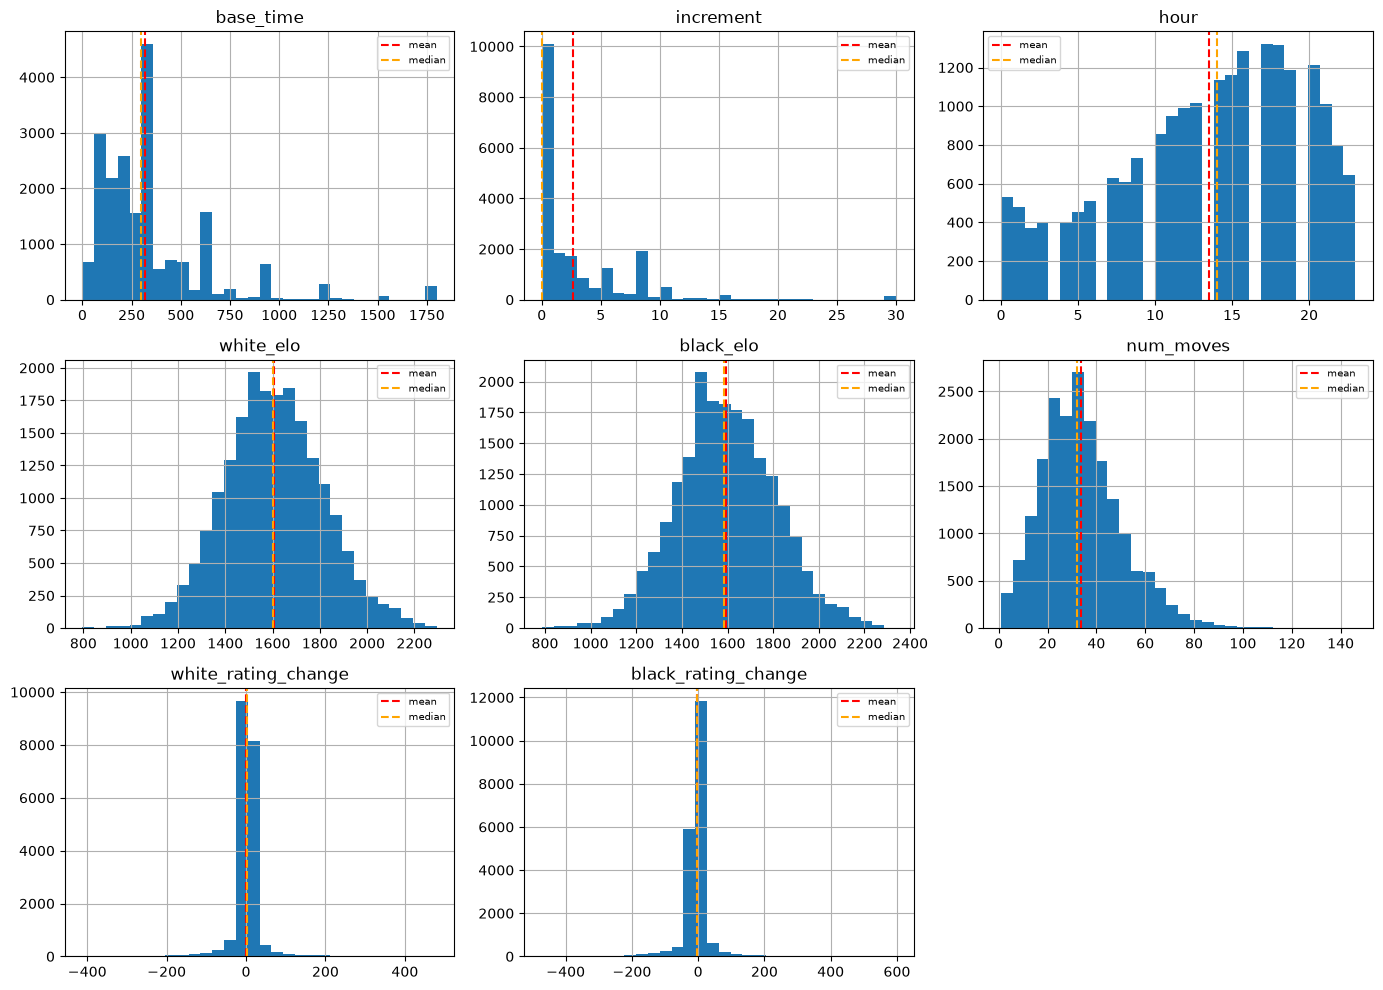

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

numeric_cols = c_dataframe.select_dtypes(include='number').columns

for i, col in enumerate(numeric_cols):
    c_dataframe[col].hist(bins=30, ax=axes[i])
    axes[i].axvline(c_dataframe[col].mean(), color='red', linestyle='--', label='mean')
    axes[i].axvline(c_dataframe[col].median(), color='orange', linestyle='--', label='median')
    axes[i].set_title(col)
    axes[i].legend(fontsize=7)

# Skjuler tomme subplots hvis det er færre kolonner enn ruter
for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [16]:
# near 0 = symmetric, positive = right tail, negative = left tail
print("Skewness per column:")
print(c_dataframe.select_dtypes(include='number').skew().round(3).to_string())

Skewness per column:
base_time              2.381
increment              2.785
hour                  -0.490
white_elo              0.080
black_elo              0.049
num_moves              0.758
white_rating_change    0.980
black_rating_change    0.290


#### White elo / Black elo:
- Begge er nesten perfekt normalfordelt rundt 1600, med skjevhet nær 0 (0,08 og 0,05). Gjennomsnitt og median ligger nesten oppå hverandre.

#### Base time og increment:
- Veldig skjeve fordelinger (2,38 og 2,79). De fleste partiene er korte, men noen få classical-partier har mye lengre tid. Fordelingen har tydelige "topper" på populære tidskontroller som 60, 180 og 300 sekunder.

#### Hour:
- Partier spilles hele døgnet, men det er færre partier om natten (UTC). Skjevheten er −0,49.

#### Num moves:
- Litt høyreskjev (0,76). De fleste partiene er mellom 20 og 45 trekk, men noen få er over 100 trekk.

#### Rating change:
- Det meste ligger nær 0 med noen veldig store unntak, så fordelingen har lange haler på begge sider.

# Distributions — Bar Plots (Categorical)

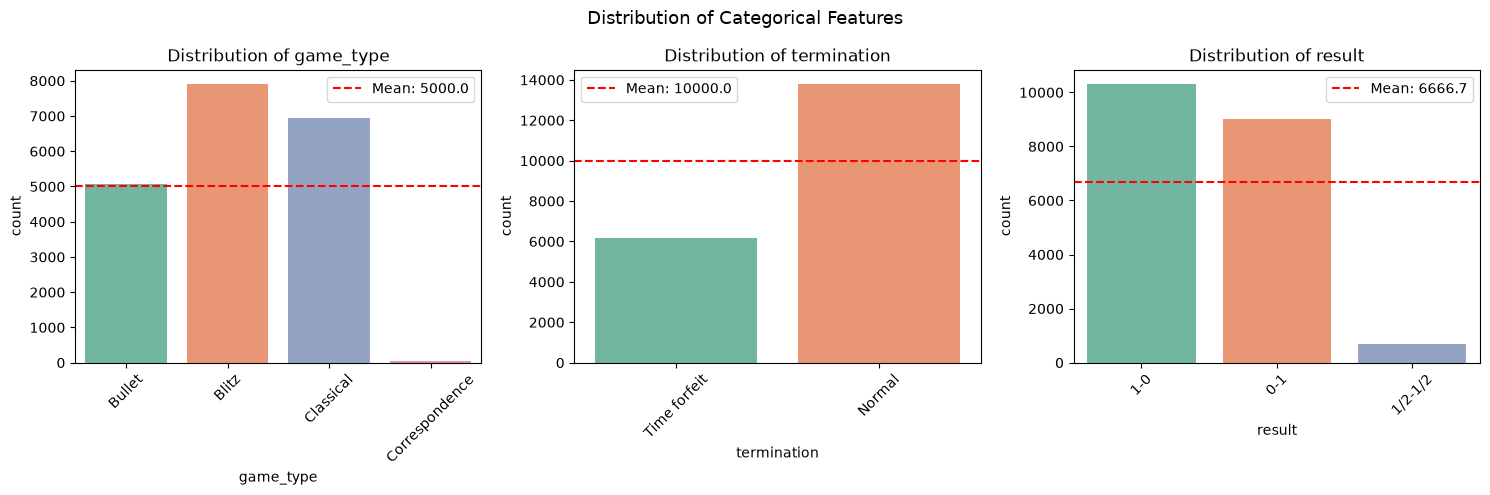

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(small_cat_cols):
    sns.countplot(data=c_dataframe, x=col, ax=axes[i], palette='Set2', hue=col, legend=False)
    mean_count = c_dataframe[col].value_counts().mean()
    axes[i].axhline(mean_count, color='red', linestyle='--', label=f'Mean: {mean_count:.1f}')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

plt.suptitle('Distribution of Categorical Features', fontsize=13)
plt.tight_layout()
plt.show()

Game type: Blitz og Classical er de største gruppene, og Correspondence er nesten usynlig i plottet.

Termination: Omtrent to tredjedeler av partiene ender normalt, og en tredjedel ender på tid.

Result: Hvit seier og svart seier er nesten like store grupper, og remis er en veldig liten gruppe (3,4 %).

## Outlier Detection — Box Plots

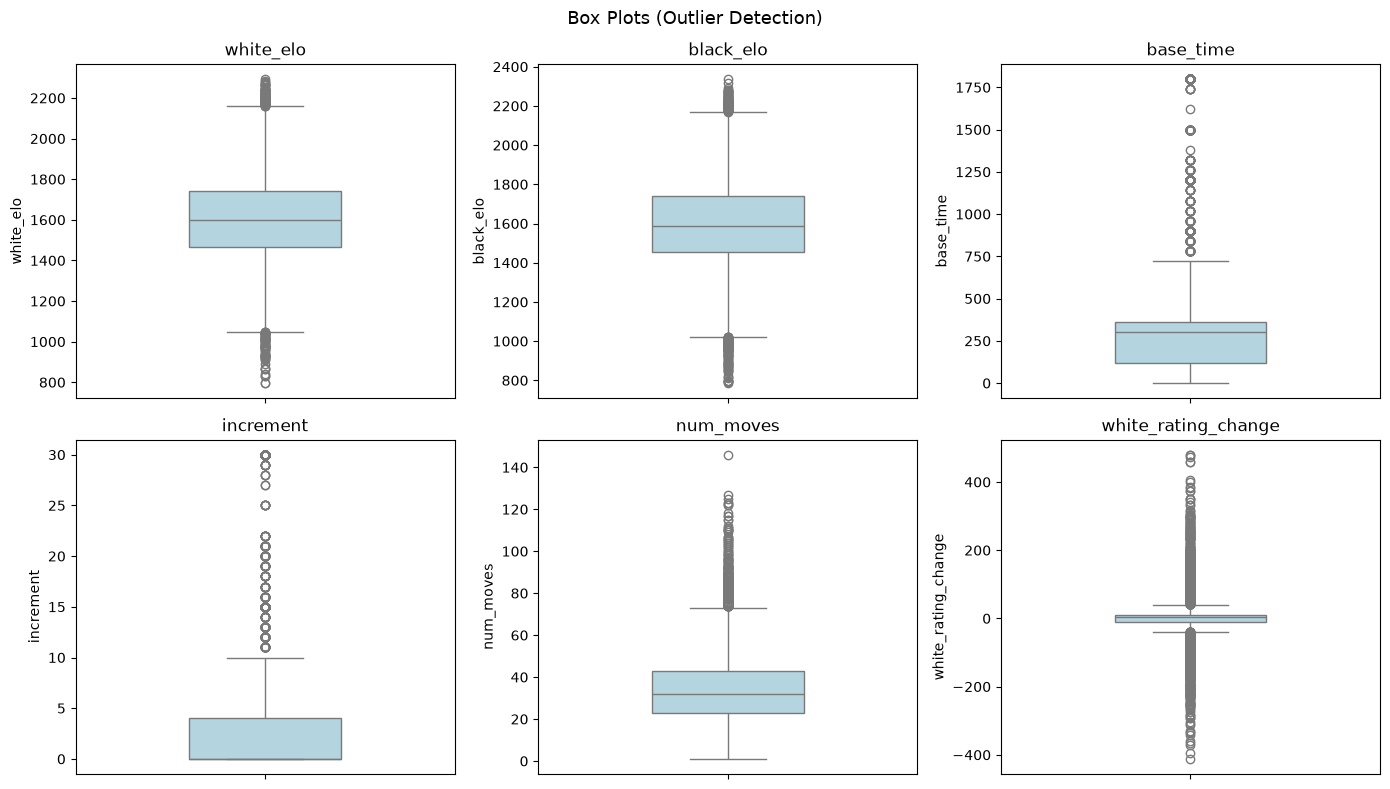

In [18]:
box_cols = ['white_elo', 'black_elo', 'base_time', 'increment', 'num_moves', 'white_rating_change']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(box_cols):
    sns.boxplot(data=c_dataframe, y=col, ax=axes[i], color='lightblue', width=0.4)
    axes[i].set_title(col)

plt.suptitle('Box Plots (Outlier Detection)', fontsize=13)
plt.tight_layout()
plt.show()

In [19]:
# Sjekker nøyaktig hvor mange outliers det er i hver numeriske kolonne ved å bruke IQR-metoden (Interquartile Range).
for col in numeric_cols:
    Q1 = c_dataframe[col].quantile(0.25)
    Q3 = c_dataframe[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((c_dataframe[col] < lower) | (c_dataframe[col] > upper)).sum()
    if n_outliers > 0:
        print(f"  {col}: {n_outliers} outliers")
    else:
        print(f"  {col}: no outliers")

  base_time: 1403 outliers
  increment: 687 outliers
  hour: no outliers
  white_elo: 168 outliers
  black_elo: 203 outliers
  num_moves: 387 outliers
  white_rating_change: 1565 outliers
  black_rating_change: 1875 outliers


#### Results:

##### Variabler med mange uteliggere:

base_time (1403) og increment (687): Dette er classical-partiene med mye tid på klokka. De er helt normale partier, de er bare sjeldnere enn bullet og blitz.

white_rating_change (1565) og black_rating_change (1875): De fleste ratingendringene er små, så alt over ca. ±40 blir regnet som uteliggere. Men disse kolonnene skal uansett ikke brukes i modellen (se preprocessing).

##### Variabler med noen få uteliggere:

white_elo (168) og black_elo (203): Veldig sterke eller veldig svake spillere. Ingen umulige verdier.

num_moves (387): Lange partier på over ca. 73 trekk.

##### Variabler uten uteliggere:

hour har ingen uteliggere.

##### Konklusjon:

Ingen av verdiene er umulige, og uteliggerne er ekte partier. Derfor beholder jeg dem. Hvis jeg fjernet for eksempel alle partiene med høy base_time, ville jeg i praksis fjernet en stor del av classical-partiene.

## Rating og resultat

Før jeg ser på korrelasjoner, lager jeg en ny kolonne `elo_diff` (hvit sin rating minus svart sin rating). I sjakk er det ikke ratingen alene som betyr noe, men forskjellen mellom spillerne. En spiller på 1800 er favoritt mot en spiller på 1500, men ikke mot en spiller på 2100.

Jeg lager også en midlertidig kolonne `white_wins` for EDA-en, slik at jeg kan se hvor ofte hvit vinner.

In [20]:
eda = c_dataframe.copy()
eda['elo_diff'] = eda['white_elo'] - eda['black_elo']
eda['white_wins'] = (eda['result'] == '1-0').astype(int)

print(f"Hvit vinner i {eda['white_wins'].mean()*100:.1f}% av partiene")

Hvit vinner i 51.6% av partiene


In [21]:
# Deler ratingforskjellen inn i grupper og ser hvor ofte hvit vinner i hver gruppe
diff_bins = [-2000, -300, -200, -100, -50, 0, 50, 100, 200, 300, 2000]
eda['diff_group'] = pd.cut(eda['elo_diff'], bins=diff_bins)

win_rate = eda.groupby('diff_group', observed=True)['white_wins'].agg(['mean', 'count'])
win_rate['mean'] = win_rate['mean'].round(3)
win_rate

,mean,count
diff_group,,
"(-2000, -300]",0.139,1269
"(-300, -200]",0.245,1460
"(-200, -100]",0.340,2799
"(-100, -50]",0.434,1915
"(-50, 0]",0.485,2262
"(0, 50]",0.546,2156
"(50, 100]",0.598,2016
"(100, 200]",0.674,2943
"(200, 300]",0.754,1619


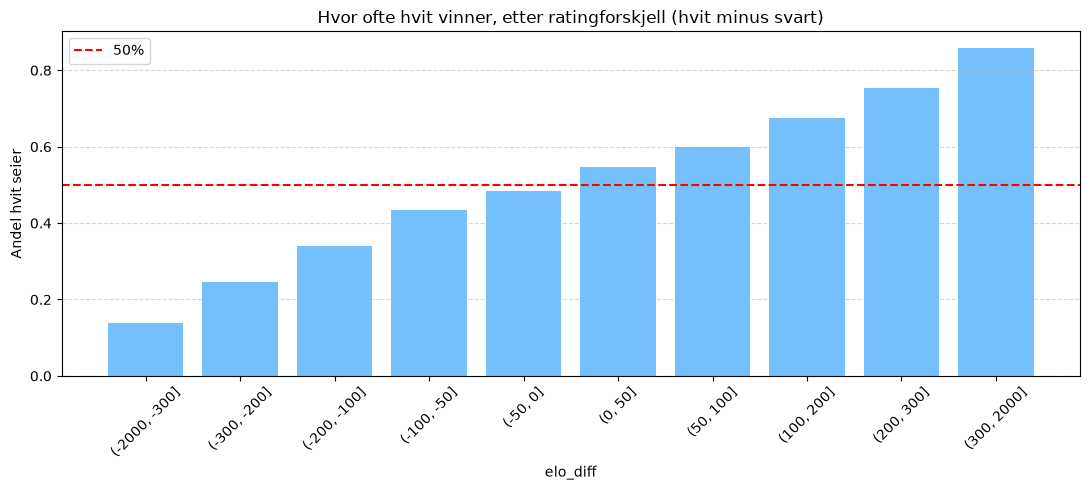

In [22]:
plt.figure(figsize=(11, 5))
plt.bar(win_rate.index.astype(str), win_rate['mean'], color='#74c0fc')
plt.axhline(0.5, color='red', linestyle='--', label='50%')
plt.title('Hvor ofte hvit vinner, etter ratingforskjell (hvit minus svart)')
plt.xlabel('elo_diff')
plt.ylabel('Andel hvit seier')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.show()

#### Results :

Dette er det tydeligste mønsteret i hele datasettet. Når hvit er mer enn 300 poeng svakere, vinner hvit bare 13,9 % av partiene. Når hvit er mer enn 300 poeng sterkere, vinner hvit 85,9 % av partiene. Imellom øker andelen jevnt for hver gruppe.

Det er også interessant at når ratingen er nesten lik (−50 til 0), vinner hvit 48,5 %, og fra 0 til +50 vinner hvit 54,6 %. Rundt 0 er det altså nesten 50/50, men hvit har en liten fordel.

Selv når ratingforskjellen er stor, er det ikke 100 % sikkert. 14 % av partiene der hvit er mye svakere, vinner hvit likevel. Det betyr at uansett hvor god modellen blir, kommer den til å ta feil på en del partier. Sjakk er ikke helt forutsigbart, spesielt ikke i bullet og blitz.

Lichess bruker i dag Glicko-2, men prinsippet er det samme som i Elo-systemet: ratingforskjellen skal gi en forventet score for partiet. Formelen fra Elo-systemet er:

E = 1 / (1 + 10^(−elo_diff / 400))

Hvis ratingforskjellen er 0, er forventet score 0,5. Hvis hvit er 400 poeng bedre, er forventet score ca. 0,91. Jeg vil sjekke om denne formelen stemmer med det vi ser i dataene.

- https://en.wikipedia.org/wiki/Elo_rating_system

In [23]:
# Sammenligner formelen med det som faktisk skjer i dataene.
# NB: forventet score teller remis som et halvt poeng, så jeg regner ut faktisk score på samme måte.
eda['actual_score'] = eda['result'].map({'1-0': 1.0, '1/2-1/2': 0.5, '0-1': 0.0})
eda['expected_score'] = 1 / (1 + 10 ** (-eda['elo_diff'] / 400))

compare = eda.groupby('diff_group', observed=True)[['expected_score', 'actual_score']].mean().round(3)
compare

,expected_score,actual_score
diff_group,,
"(-2000, -300]",0.095,0.149
"(-300, -200]",0.199,0.262
"(-200, -100]",0.305,0.361
"(-100, -50]",0.395,0.454
"(-50, 0]",0.465,0.505
"(0, 50]",0.536,0.565
"(50, 100]",0.607,0.614
"(100, 200]",0.698,0.690
"(200, 300]",0.804,0.768


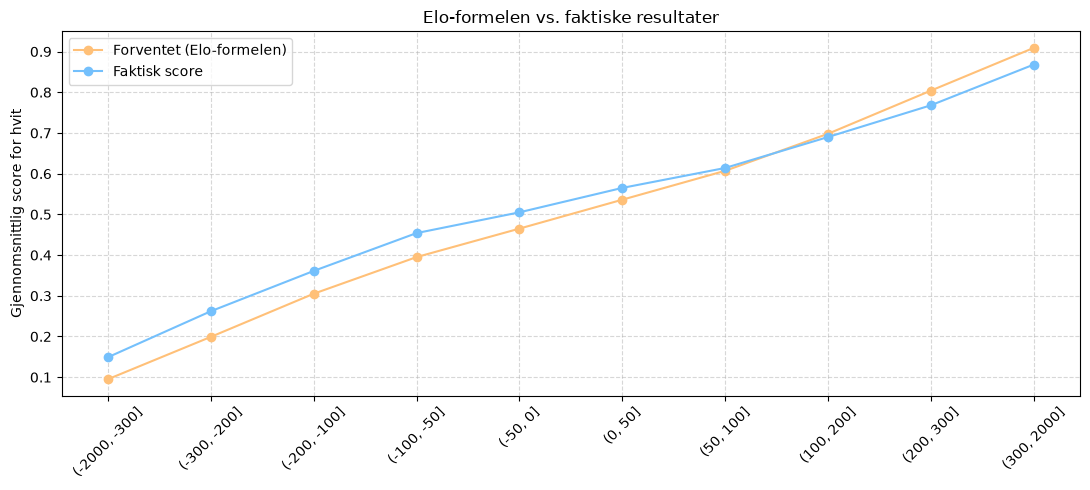

In [24]:
plt.figure(figsize=(11, 5))
x = np.arange(len(compare))
plt.plot(x, compare['expected_score'], marker='o', color='#ffc078', label='Forventet (Elo-formelen)')
plt.plot(x, compare['actual_score'], marker='o', color='#74c0fc', label='Faktisk score')
plt.xticks(x, compare.index.astype(str), rotation=45)
plt.title('Elo-formelen vs. faktiske resultater')
plt.ylabel('Gjennomsnittlig score for hvit')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Results :
Formelen og de faktiske resultatene følger hverandre ganske godt, men ikke perfekt:

- Når ratingforskjellen er liten (−50 til +100), er de nesten like, for eksempel 0,607 forventet mot 0,614 faktisk.
- Når hvit er mye svakere (under −300), forventer formelen 0,095, men hvit får faktisk 0,149.
- Når hvit er mye sterkere (over +300), forventer formelen 0,909, men hvit får bare 0,868.

Den svakere spilleren gjør det altså litt bedre enn formelen sier, i begge retninger. En mulig grunn er at mange ratinger i 2013 var usikre, særlig for nye spillere som starter på 1500, og at korte tidskontroller gir mer tilfeldige resultater. Jeg vet ikke sikkert hva årsaken er, men det betyr at det kan være litt å hente for en modell som lærer fra dataene i stedet for å bare bruke formelen.

## Correlation Analysis

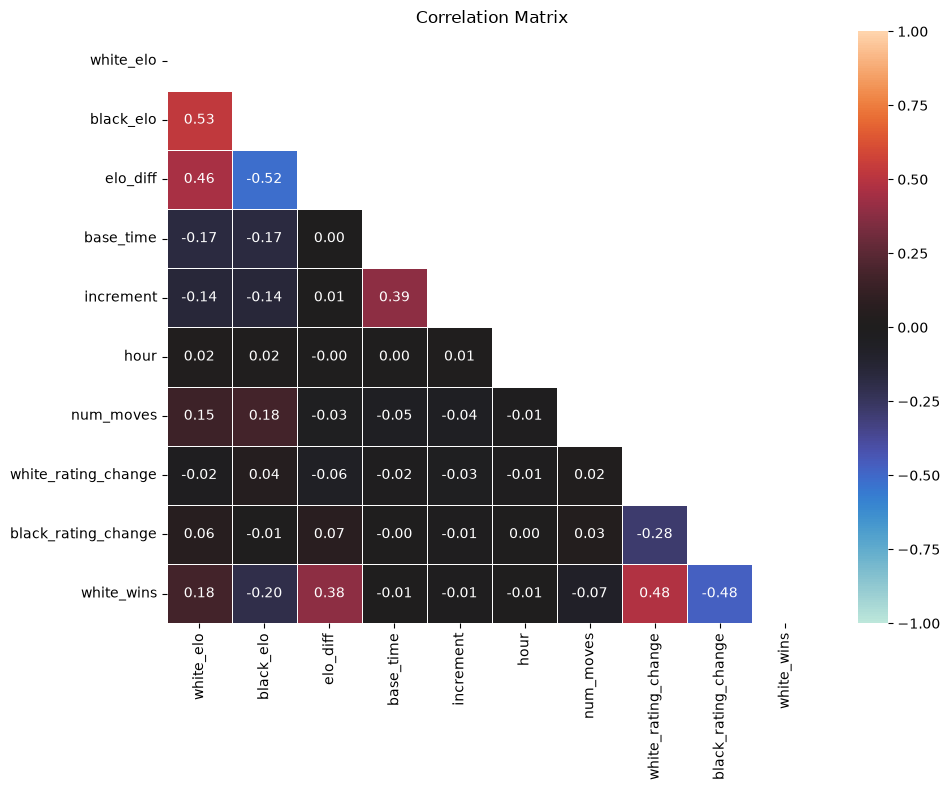

In [25]:
corr_cols = ['white_elo', 'black_elo', 'elo_diff', 'base_time', 'increment', 'hour',
             'num_moves', 'white_rating_change', 'black_rating_change', 'white_wins']
corr = eda[corr_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, cmap='icefire', center=0,
            fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [26]:
print("Correlations with white_wins (sorted):")
target_corr = corr['white_wins'].drop('white_wins').sort_values(ascending=False)
print(target_corr.round(3).to_string())

Correlations with white_wins (sorted):
white_rating_change    0.477
elo_diff               0.384
white_elo              0.176
hour                  -0.006
base_time             -0.007
increment             -0.011
num_moves             -0.074
black_elo             -0.197
black_rating_change   -0.476


##### Results :

#### Sterk sammenheng (men kan IKKE brukes):

white_rating_change (0,48) og black_rating_change (−0,48): Dette er de sterkeste korrelasjonene, men de er regnet ut **etter** partiet. Se cellen under.

#### Moderat positiv sammenheng:

elo_diff (0,38): Ratingforskjellen er klart den viktigste variabelen vi faktisk kan bruke.

#### Svak sammenheng:

white_elo (0,18) og black_elo (−0,20): Hver rating alene har en svakere sammenheng enn forskjellen mellom dem. Det passer med det jeg skrev over: det er forskjellen som betyr noe.

num_moves (−0,07): Litt lavere sjanse for hvit seier i lange partier. Men dette er også informasjon vi først har etter partiet.

#### Ingen tydelig sammenheng:

hour (−0,006), base_time (−0,007) og increment (−0,011): Tidspunktet på døgnet og tidskontrollen har nesten ingen sammenheng med om hvit vinner.

I heatmapen ser vi også at white_elo og black_elo har en positiv sammenheng med hverandre. Det er fordi Lichess prøver å sette opp partier mellom spillere med lignende rating.

In [27]:
# Hvordan henger white_rating_change sammen med resultatet?
# Hvis hvit vinner, går ratingen opp. Hvis hvit taper, går den ned.
eda.groupby('result')['white_rating_change'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
result,,,,,,,,
0-1,8982.0,-19.3,32.4,-412.0,-16.0,-11.0,-7.0,0.0
1-0,10309.0,18.2,34.5,0.0,7.0,10.0,15.0,480.0
1/2-1/2,668.0,0.8,14.5,-136.0,-4.0,0.0,4.0,126.0


#### Results :
Her ser vi tydelig hvorfor `white_rating_change` er data leakage. Når hvit vinner (1-0), er ratingendringen alltid 0 eller høyere (min = 0). Når svart vinner (0-1), er den alltid 0 eller lavere (max = 0). Hvis modellen fikk denne kolonnen, kunne den nesten bare se på fortegnet og vite svaret.

Det samme gjelder `black_rating_change`, `num_moves` og `termination`. Alt dette vet vi først når partiet er ferdig. Målet er å forutsi resultatet **før** partiet starter, så disse kolonnene må fjernes før modelltreningen.

- https://www.geeksforgeeks.org/machine-learning/what-is-data-leakage/

## Spilltype, tidskontroll og åpning

In [28]:
# game_type ser ut til å være laget ut fra tidskontrollen. Jeg sjekker det ved å se
# på hvilke base_time-verdier som finnes i hver spilltype.
eda.groupby('game_type')['base_time'].agg(['min', 'median', 'max'])

,min,median,max
game_type,,,
Blitz,0.0,240.0,420.0
Bullet,0.0,60.0,120.0
Classical,60.0,480.0,1800.0
Correspondence,NaN,NaN,NaN


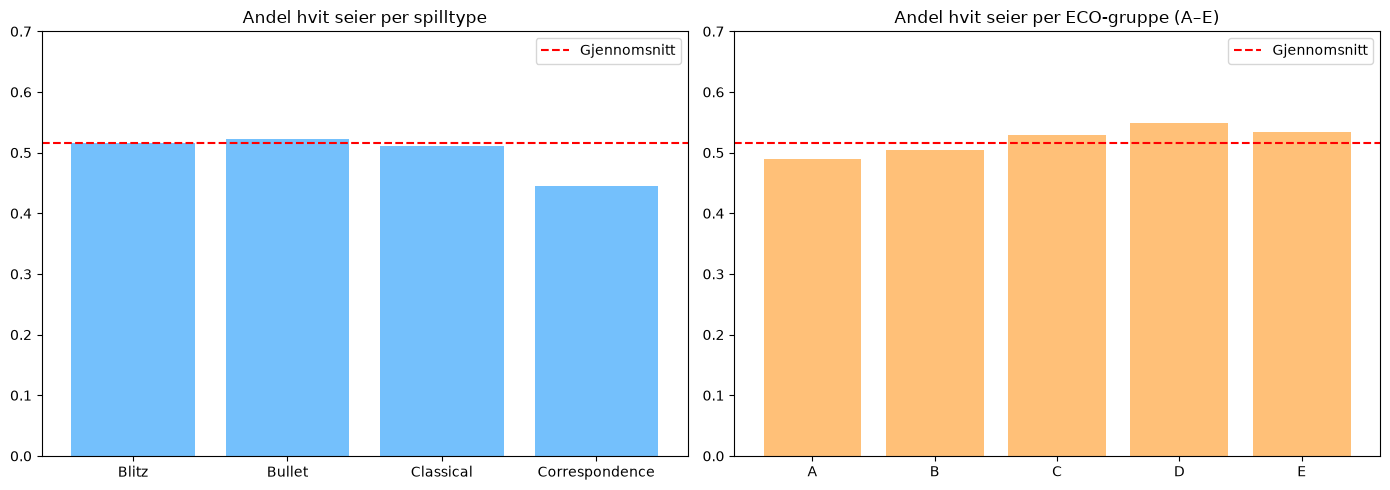

      mean  count
eco              
A    0.489   4474
B    0.504   5384
C    0.529   7087
D    0.548   2733
E    0.534    322


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

type_rate = eda.groupby('game_type')['white_wins'].mean()
axes[0].bar(type_rate.index, type_rate.values, color='#74c0fc')
axes[0].axhline(eda['white_wins'].mean(), color='red', linestyle='--', label='Gjennomsnitt')
axes[0].set_title('Andel hvit seier per spilltype')
axes[0].set_ylim(0, 0.7)
axes[0].legend()

eco_rate = eda.groupby(eda['eco'].str[0])['white_wins'].mean()
axes[1].bar(eco_rate.index, eco_rate.values, color='#ffc078')
axes[1].axhline(eda['white_wins'].mean(), color='red', linestyle='--', label='Gjennomsnitt')
axes[1].set_title('Andel hvit seier per ECO-gruppe (A–E)')
axes[1].set_ylim(0, 0.7)
axes[1].legend()

plt.tight_layout()
plt.show()

print(eda.groupby(eda['eco'].str[0])['white_wins'].agg(['mean', 'count']).round(3))

#### Results :
Spilltype: game_type er laget ut fra tidskontrollen. Bullet har base_time opp til 120 sekunder, Blitz opp til 420 og Classical fra 60 og oppover (Lichess regner ut en estimert varighet ut fra både base_time og increment, derfor overlapper de litt). Det betyr at game_type ikke gir noe ny informasjon som base_time og increment ikke allerede har.

Andelen hvit seier er nesten den samme i alle spilltypene (51–52 %), bortsett fra correspondence, men der er det bare 45 partier.

ECO-gruppe: Her er det litt mer forskjell. I A-åpninger (flankåpninger som English Opening) vinner hvit 48,9 %, mens i D-åpninger (Queen's Gambit-familien) vinner hvit 54,8 %. Forskjellen er ikke stor, og den kan også henge sammen med hvem som velger hvilke åpninger.

In [30]:
# De 10 vanligste åpningsfamiliene og hvor ofte hvit vinner i hver av dem
top_families = eda['opening_family'].value_counts().head(10).index
family_rate = (eda[eda['opening_family'].isin(top_families)]
               .groupby('opening_family')['white_wins'].agg(['mean', 'count'])
               .sort_values('mean', ascending=False))
family_rate['mean'] = family_rate['mean'].round(3)
family_rate

,mean,count
opening_family,,
Philidor Defense,0.601,745
Italian Game,0.543,657
Scandinavian Defense,0.537,883
Queen's Pawn Game,0.534,1342
Caro-Kann Defense,0.504,663
English Opening,0.495,570
King's Pawn Game,0.475,966
Van't Kruijs Opening,0.467,493
French Defense,0.463,1528


#### Results :
Det er faktisk en del forskjell mellom åpningene. I Philidor Defense vinner hvit 60,1 %, mens i Sicilian Defense vinner hvit bare 45,1 %. Det er en forskjell på 15 prosentpoeng.

Men jeg må være forsiktig med å tolke dette. Det er svart som velger Philidor eller Sicilian, og det kan godt være at svakere spillere velger Philidor oftere, og sterkere spillere velger Sicilian. Da er det egentlig ratingen som forklarer forskjellen, og ikke åpningen i seg selv. Jeg vet ikke ennå om åpningen gir noe ekstra informasjon i tillegg til ratingen, men det får modellene vise.

# Target Variable Analysis

In [31]:
print(eda['result'].value_counts())
print()
print((eda['result'].value_counts(normalize=True) * 100).round(1))

result
1-0        10324
0-1         9004
1/2-1/2      672
Name: count, dtype: int64

result
1-0        51.6
0-1        45.0
1/2-1/2     3.4
Name: proportion, dtype: float64


Med tre klasser har remis bare 3,4 % av partiene (672 partier). En modell med tre klasser ville hatt svært lite data å lære fra for remis, og den ville sannsynligvis aldri gjettet remis i det hele tatt.

Beslutning: Jeg forenkler dette til en binær klassifikasjon: **hvit vinner (1)** eller **hvit vinner ikke (0)**, der "vinner ikke" er både svart seier og remis. Det er samme tankegang som bestått/ikke bestått i forrige prosjekt.

I motsetning til forrige prosjekt, der 92 % besto, er klassene her nesten balanserte (51,6 % mot 48,4 %). Det betyr at accuracy er et mer ærlig mål denne gangen, og at jeg ikke trenger å gjøre så mye for å håndtere klasseubalanse.

## EDA Summary

Hva vi fant:

Vi har 20 000 partier og 15 kolonner. Dataene er ryddige, uten duplikater, og det mangler veldig lite data (under 0,25 % i alle kolonnene).

Ratingforskjellen mellom spillerne (`elo_diff`) er klart den viktigste variabelen (r = 0,38). Hvit vinner 14 % når hvit er mye svakere, og 86 % når hvit er mye sterkere. Elo-formelen beskriver dette ganske godt, men den svakere spilleren gjør det litt bedre enn formelen forventer.

Tidskontroll og tidspunkt har nesten ingen sammenheng med resultatet. Åpningene viser noen forskjeller, men det er usikkert om det er åpningen eller spillerne som forklarer forskjellen.

`white_rating_change`, `black_rating_change`, `num_moves` og `termination` har sterke sammenhenger med resultatet, men de er regnet ut etter partiet, så de er data leakage.

Beslutninger for preprocessing:

Correspondence-partiene og partiene uten rating fjernes (til sammen under 0,5 % av dataene).

Jeg lager target-kolonnen `white_wins` (1 = hvit vinner, 0 = remis eller svart vinner).

Kolonnene som først er kjent etter partiet fjernes, og jeg lager nye features: `elo_diff`, `avg_elo` og `eco_group`.

Åpningene forenkles til de 10 vanligste familiene + `Other`, og kategoriene one-hot encodes.

Jeg deler datasettet før encoding og scaling som bruker informasjon fra dataene, og bruker stratification.

# DATA PREPROCESSING

In [32]:
df = c_dataframe.copy()

# Fjerner correspondence-partiene (45 partier). De har ingen klokke, så base_time og increment mangler,
# og et parti som varer i flere dager er en helt annen type sjakk enn bullet og blitz.
df = df[df['game_type'] != 'Correspondence']

# Fjerner partiene der ratingen mangler. Det er bare rundt 0,2 % av partiene,
# og jeg vil ikke gjette ratingen til en spiller, siden ratingen er den viktigste informasjonen vi har.
df = df.dropna(subset=['white_elo', 'black_elo'])

print(f"{df.shape[0]} rows igjen")
df.isnull().sum()

19922 rows igjen


game_type              0
time_control           0
base_time              0
increment              0
hour                   0
white_elo              0
black_elo              0
eco                    0
opening                0
opening_family         0
num_moves              0
termination            0
white_rating_change    0
black_rating_change    0
result                 0
dtype: int64

In [33]:
# Lager target-kolonnen: 1 hvis hvit vinner, 0 hvis partiet ender remis eller svart vinner.
df['white_wins'] = (df['result'] == '1-0').astype(int)

print(df['white_wins'].value_counts())
print(f"\nWhite wins: {df['white_wins'].mean()*100:.1f}%")
print(f"Not white win: {(1-df['white_wins'].mean())*100:.1f}%")

white_wins
1    10293
0     9629
Name: count, dtype: int64

White wins: 51.7%
Not white win: 48.3%


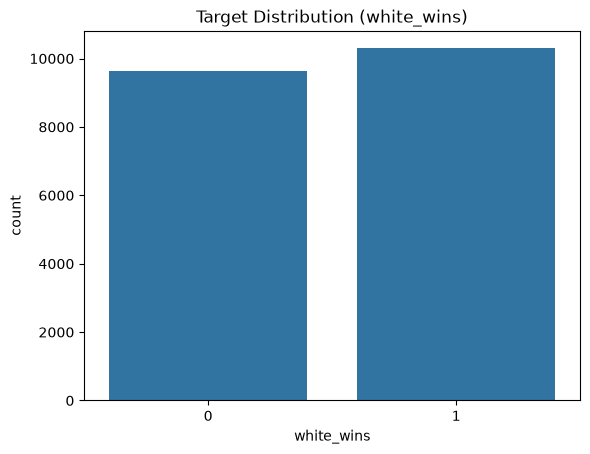

In [34]:
sns.countplot(x='white_wins', data=df)
plt.title('Target Distribution (white_wins)')
plt.show()

In [35]:
# Fjerner kolonner som modellen IKKE får lov til å bruke.
#
# result: det er selve svaret, target er laget fra denne.
# white_rating_change / black_rating_change: blir regnet ut ETTER partiet, ut fra resultatet. Data leakage.
# num_moves: vi vet ikke hvor langt partiet blir før det er spilt.
# termination: vi vet ikke om partiet ender på tid eller normalt før det er ferdig.
#
# Min første tanke var å beholde num_moves, siden korte partier kanskje henger sammen med
# at en spiller gjør en stor feil tidlig. Men modellen skal brukes FØR partiet, og da finnes ikke denne informasjonen.

leakage_cols = ['result', 'white_rating_change', 'black_rating_change', 'num_moves', 'termination']
df = df.drop(columns=leakage_cols)

# time_control er bare teksten "300+8", og den er allerede delt opp i base_time og increment.
# game_type er laget av Lichess ut fra tidskontrollen, så den gir ingen ny informasjon.
# opening har 1309 unike verdier, altfor mange. Jeg bruker opening_family og ECO-gruppen i stedet.
df = df.drop(columns=['time_control', 'game_type', 'opening'])

df.columns.tolist()

['base_time',
 'increment',
 'hour',
 'white_elo',
 'black_elo',
 'eco',
 'opening_family',
 'white_wins']

Etter at jeg har fjernet kolonnene, har vi bare informasjon som er kjent før partiet starter: tidskontrollen (`base_time`, `increment`), tidspunktet (`hour`), ratingene og åpningen. Det er dette modellen får jobbe med.

Det er verdt å nevne at åpningen egentlig ikke er helt kjent før partiet starter, siden den bestemmes av de første trekkene. Men i praksis vet mange spillere hvilken åpning de kommer til å spille, så jeg velger å beholde den. Det er en avgjørelse jeg tar bevisst, og jeg kommer tilbake til om den faktisk hjelper modellen.

In [36]:
# Feature engineering:
# elo_diff: forskjellen i rating. Fra EDA-en vet vi at dette er den viktigste variabelen.
# avg_elo: gjennomsnittlig rating i partiet. Kanskje partier mellom sterke spillere oppfører seg annerledes?
# eco_group: første bokstav i ECO-koden (A–E), en grov gruppering av åpningene.

df['elo_diff'] = df['white_elo'] - df['black_elo']
df['avg_elo'] = (df['white_elo'] + df['black_elo']) / 2
df['eco_group'] = df['eco'].str[0]
df = df.drop(columns=['eco'])

df.head()

,base_time,increment,hour,white_elo,black_elo,opening_family,white_wins,elo_diff,avg_elo,eco_group
0,60.0,0.0,23,1624.0,1471.0,Modern Defense,1,153.0,1547.5,B
1,180.0,2.0,20,1742.0,1797.0,Caro-Kann Defense,0,-55.0,1769.5,B
2,60.0,1.0,12,1558.0,1934.0,Queen's Pawn Game,0,-376.0,1746.0,D
3,120.0,2.0,10,1553.0,1461.0,"Nimzowitsch Defense, Declined Variation",1,92.0,1507.0,B
4,900.0,8.0,23,1360.0,1419.0,Sicilian Defense,1,-59.0,1389.5,B


Jeg bruker ingen ordinal encoding i dette prosjektet. I forrige prosjekt passet det for diet_quality (Poor < Fair < Good), men her har ingen av de kategoriske variablene en naturlig rekkefølge:

- **eco_group (A–E):** bokstavene er bare en måte å sortere åpninger på (A = flankåpninger, B = halvåpne spill mot e4, osv.). En E-åpning er ikke "mer" enn en A-åpning. Hvis jeg setter A = 0 og E = 4, vil modellen tro at det finnes en rekkefølge som ikke eksisterer.
- **opening_family:** har ingen rekkefølge, og har 199 forskjellige verdier.

Derfor bruker jeg **one-hot encoding** for begge. For opening_family ville one-hot gitt 199 kolonner, og mange åpninger finnes bare i noen få partier. Jeg beholder derfor de 10 vanligste åpningsfamiliene og samler resten i en kategori `Other`.

Jeg vurderte også **target encoding** for opening_family (erstatte hver åpning med andelen hvit seier i den åpningen). Det kunne fungert, men med veldig få partier i mange av åpningene ville verdiene blitt tilfeldige, og det er lett å lekke informasjon fra target hvis man ikke er forsiktig. One-hot med de vanligste åpningene er enklere og tryggere.

Hvilke 10 åpninger som er "vanligst", må bestemmes ut fra **treningsdataene**, ikke hele datasettet. Derfor gjør jeg dette etter splittingen.

- https://www.geeksforgeeks.org/machine-learning/one-hot-encoding-vs-label-encoding/

In [37]:
# separating features and target
features = df.drop('white_wins', axis=1)
targets = df['white_wins']

In [38]:
random_state = 13

In [39]:
# Stratified splitting — preserves the white_wins distribution in all three sets
# 75% train, 12.5% validation, 12.5% test
#
# Viktig: etter at jeg fjernet rader over (correspondence og manglende rating) har indeksen "hull".
# I forrige prosjekt brukte jeg .iloc[indices], men .iloc bruker posisjon og ikke indeks-navnet.
# Det fungerte der fordi ingen rader var fjernet. Her bruker jeg .loc, som henter radene ut fra indeks-navnet.

train_indices = df.groupby('white_wins').sample(frac=0.75, random_state=random_state).index
train_features = features.loc[train_indices]
train_targets = targets.loc[train_indices]

testvalidation_data = df.drop(train_indices, axis=0)
validation_indices = testvalidation_data.groupby('white_wins').sample(frac=0.5, random_state=random_state).index

validation_features = features.loc[validation_indices]
validation_targets = targets.loc[validation_indices]

test_indices = testvalidation_data.drop(validation_indices, axis=0).index
test_features = features.loc[test_indices]
test_targets = targets.loc[test_indices]

print(f"Train: {len(train_features)}, Validation: {len(validation_features)}, Test: {len(test_features)}")

# Checking that the distribution is the same in all three sets
print("\nTrain:")
print(train_targets.value_counts() / train_targets.count())
print("\nValidation:")
print(validation_targets.value_counts() / validation_targets.count())
print("\nTest:")
print(test_targets.value_counts() / test_targets.count())

Train: 14942, Validation: 2490, Test: 2490

Train:
white_wins
1    0.516664
0    0.483336
Name: count, dtype: float64

Validation:
white_wins
1    0.516466
0    0.483534
Name: count, dtype: float64

Test:
white_wins
1    0.516867
0    0.483133
Name: count, dtype: float64


- https://www.geeksforgeeks.org/machine-learning/splitting-data-for-machine-learning-models/

Datasettet er delt inn i 14 942 partier for trening, 2490 for validering og 2490 for test. Klassefordelingen er nesten helt lik i alle tre settene (51,7 % hvit seier), så den stratifiserte splittingen fungerer som forventet.

Siden klassene allerede er ganske balanserte, ville det sannsynligvis gått bra uten stratification også, men det koster ingenting å gjøre det, og det sikrer at test-resultatene blir mer pålitelige.

In [40]:
# Finner de 10 vanligste åpningsfamiliene i TRENINGSDATAENE, og setter resten til "Other"
top_openings = train_features['opening_family'].value_counts().head(10).index

for data in [train_features, validation_features, test_features]:
    data['opening_family'] = data['opening_family'].where(data['opening_family'].isin(top_openings), 'Other')

print(train_features['opening_family'].value_counts())

opening_family
Other                   7549
Sicilian Defense        1562
French Defense          1150
Queen's Pawn Game        979
King's Pawn Game         710
Scandinavian Defense     639
Philidor Defense         556
Caro-Kann Defense        496
Italian Game             488
English Opening          440
Van't Kruijs Opening     373
Name: count, dtype: int64


In [41]:
# One-hot encoding for eco_group og opening_family
train_features = pd.get_dummies(train_features, columns=['eco_group', 'opening_family'], dtype=float)
validation_features = pd.get_dummies(validation_features, columns=['eco_group', 'opening_family'], dtype=float)
test_features = pd.get_dummies(test_features, columns=['eco_group', 'opening_family'], dtype=float)

# get_dummies lager bare kolonner for kategoriene som finnes i hvert sett.
# Hvis en kategori mangler i validerings- eller testsettet, får settene forskjellige kolonner.
# reindex sørger for at alle settene får nøyaktig de samme kolonnene som treningssettet (manglende = 0).
validation_features = validation_features.reindex(columns=train_features.columns, fill_value=0)
test_features = test_features.reindex(columns=train_features.columns, fill_value=0)

print(f"Antall kolonner nå: {train_features.shape[1]}")
print(f"\nKolonner:\n{list(train_features.columns)}")

Antall kolonner nå: 23

Kolonner:
['base_time', 'increment', 'hour', 'white_elo', 'black_elo', 'elo_diff', 'avg_elo', 'eco_group_A', 'eco_group_B', 'eco_group_C', 'eco_group_D', 'eco_group_E', 'opening_family_Caro-Kann Defense', 'opening_family_English Opening', 'opening_family_French Defense', 'opening_family_Italian Game', "opening_family_King's Pawn Game", 'opening_family_Other', 'opening_family_Philidor Defense', "opening_family_Queen's Pawn Game", 'opening_family_Scandinavian Defense', 'opening_family_Sicilian Defense', "opening_family_Van't Kruijs Opening"]


I forrige prosjekt brukte jeg `pd.get_dummies` på hvert sett for seg, og det gikk bra fordi alle kategoriene fantes i alle tre settene. Det er ikke garantert. Hvis for eksempel `eco_group_E` (som bare har 322 partier) hadde manglet helt i testsettet, ville testsettet fått én kolonne mindre enn treningssettet, og modellen ville feilet eller brukt feil kolonner. Derfor bruker jeg `reindex` her, slik at kolonnene alltid er like.

In [42]:
# Lagrer gjennomsnitt og standardavvik for elo_diff før standardiseringen.
# Jeg trenger dem senere for Elo-baseline-modellen, som jobber med den ekte ratingforskjellen.
elo_diff_mean = train_features['elo_diff'].mean()
elo_diff_std = train_features['elo_diff'].std()

train_mean = train_features.mean()
train_std = train_features.std()

train_features = (train_features - train_mean) / train_std
validation_features = (validation_features - train_mean) / train_std
test_features = (test_features - train_mean) / train_std

print("Train (first rows):")
print(train_features.head())

Train (first rows):
       base_time  increment      hour  white_elo  black_elo  elo_diff  \
9057   -0.667381  -0.611237 -0.892595  -1.189285   0.400649 -1.610026   
19818  -0.057112   2.877877 -1.218440   1.354172   1.150459  0.151884   
16737  -0.870805  -0.611237 -0.729673  -0.169979  -0.431963  0.281861   
14984  -0.057112   1.714839  0.410784  -0.145939   0.897455 -1.085304   
12360  -0.260535  -0.611237  0.736629   0.652197   0.363848  0.272233   

        avg_elo  eco_group_A  eco_group_B  eco_group_C  ...  \
9057  -0.431586     1.845926    -0.607179    -0.735967  ...   
19818  1.432032    -0.541697    -0.607179     1.358665  ...   
16737 -0.348100     1.845926    -0.607179    -0.735967  ...   
14984  0.443668    -0.541697     1.646851    -0.735967  ...   
12360  0.578323    -0.541697     1.646851    -0.735967  ...   

       opening_family_English Opening  opening_family_French Defense  \
9057                        -0.174180                      -0.288749   
19818             

Standardisering av features

Ratingene ligger rundt 800–2300, base_time går fra 0 til 1800 sekunder, og one-hot kolonnene er bare 0 eller 1. Modeller som KNN og SGDClassifier bruker avstander og vekter, og vil da la de store tallene dominere. Derfor standardiserer jeg alle features:

z = (verdi − gjennomsnitt) / standardavvik

Gjennomsnittet og standardavviket regnes ut **kun fra treningsdataene**, og de samme verdiene brukes på validerings- og testdataene. Dette er for å unngå data leakage.

In [43]:
print(train_features.columns.tolist())

['base_time', 'increment', 'hour', 'white_elo', 'black_elo', 'elo_diff', 'avg_elo', 'eco_group_A', 'eco_group_B', 'eco_group_C', 'eco_group_D', 'eco_group_E', 'opening_family_Caro-Kann Defense', 'opening_family_English Opening', 'opening_family_French Defense', 'opening_family_Italian Game', "opening_family_King's Pawn Game", 'opening_family_Other', 'opening_family_Philidor Defense', "opening_family_Queen's Pawn Game", 'opening_family_Scandinavian Defense', 'opening_family_Sicilian Defense', "opening_family_Van't Kruijs Opening"]


# MODEL TRAINING & HYPERPARAMETER TUNING

Jeg starter med en enkel **Elo-baseline** som ikke lærer noe fra dataene: den gjetter at hvit vinner hvis hvit har høyere rating. Dette er det en sjakkspiller selv ville gjettet, så modellene mine må helst slå denne.

Deretter trener og justerer jeg de samme modellene som i forrige prosjekt: Decision Tree, Gaussian Naive Bayes, KNN og SGDClassifier. Til slutt lager jeg min egen logistiske regresjon fra bunnen av, siden min egen Linear Classifier gjorde det dårlig sist.

In [44]:
# Lager funksjoner for å evaluere modellen
# Brukes til å evaluere hyperparameter-tuning
def validation(model):
    train_predictions = model.predict(train_features)
    validation_predictions = model.predict(validation_features)
    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.3f} Validation: {accuracy_score(validation_targets, validation_predictions):.3f}')
    print(f'Training Precision: {precision_score(train_targets, train_predictions):.3f} Validation: {precision_score(validation_targets, validation_predictions):.3f}')
    print(f'Training Recall: {recall_score(train_targets, train_predictions):.3f} Validation: {recall_score(validation_targets, validation_predictions):.3f}')
    print(f'Training F1: {f1_score(train_targets, train_predictions):.3f} Validation: {f1_score(validation_targets, validation_predictions):.3f}')


# Ekstra metrikker: spesifisitet og NPV – "speilbildet" av recall og precision for klassen "hvit vinner ikke"
def extra_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    return specificity, npv


# Used for final testing
def test(model):
    train_predictions = model.predict(train_features)
    validation_predictions = model.predict(validation_features)
    test_predictions = model.predict(test_features)
    spec, npv = extra_metrics(test_targets, test_predictions)

    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.3f} Validation: {accuracy_score(validation_targets, validation_predictions):.3f} Testing: {accuracy_score(test_targets, test_predictions):.3f}')
    print(f'Training Precision: {precision_score(train_targets, train_predictions):.3f} Validation: {precision_score(validation_targets, validation_predictions):.3f} Testing: {precision_score(test_targets, test_predictions):.3f}')
    print(f'Training Recall: {recall_score(train_targets, train_predictions):.3f} Validation: {recall_score(validation_targets, validation_predictions):.3f} Testing: {recall_score(test_targets, test_predictions):.3f}')
    print(f'Training F1: {f1_score(train_targets, train_predictions):.3f} Validation: {f1_score(validation_targets, validation_predictions):.3f} Testing: {f1_score(test_targets, test_predictions):.3f}')
    print(f'Specificity (TNR) - Testing: {spec:.3f}')
    print(f'NPV               - Testing: {npv:.3f}')

    return {
        'accuracy': accuracy_score(test_targets, test_predictions),
        'precision': precision_score(test_targets, test_predictions),
        'recall': recall_score(test_targets, test_predictions),
        'f1': f1_score(test_targets, test_predictions),
        'specificity': spec,
        'npv': npv
    }

In [45]:
def average_validation(model_class, params, n_runs=5):
    accs, precs, recs, f1s = [], [], [], []
    for _ in range(n_runs):
        model = model_class(**params)  # no random_state here
        model.fit(train_features, train_targets)
        pred = model.predict(validation_features)
        accs.append(accuracy_score(validation_targets, pred))
        precs.append(precision_score(validation_targets, pred))
        recs.append(recall_score(validation_targets, pred))
        f1s.append(f1_score(validation_targets, pred))
    print(f"Avg over {n_runs} runs — Accuracy: {np.mean(accs):.3f}, "
          f"Precision: {np.mean(precs):.3f}, Recall: {np.mean(recs):.3f}, F1: {np.mean(f1s):.3f}")

## Elo Baseline

In [46]:
# NB: ClassifierMixin må stå FØR BaseEstimator.
# I forrige prosjekt skrev jeg (BaseEstimator, ClassifierMixin), men i nyere scikit-learn gjør den rekkefølgen
# at sklearn ikke skjønner at det er en klassifiseringsmodell, og ROC-kurven feiler.
class EloBaseline(ClassifierMixin, BaseEstimator):
    # En "modell" som ikke lærer noe. Den bruker bare Elo-formelen:
    # sannsynligheten for at hvit vinner = 1 / (1 + 10^(-elo_diff / 400))
    # Siden features er standardisert, må jeg regne elo_diff tilbake til ekte ratingpoeng først.

    def __init__(self, diff_mean=0.0, diff_std=1.0):
        self.diff_mean = diff_mean
        self.diff_std = diff_std

    def fit(self, x, y):
        # Ingenting å lære, men sklearn forventer at classes_ finnes etter fit
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, x):
        real_diff = x['elo_diff'] * self.diff_std + self.diff_mean
        p_white = 1 / (1 + 10 ** (-real_diff / 400))
        return np.column_stack([1 - p_white, p_white])

    def predict(self, x):
        return (self.predict_proba(x)[:, 1] >= 0.5).astype(int)

In [47]:
elo_baseline = EloBaseline(diff_mean=elo_diff_mean, diff_std=elo_diff_std)
elo_baseline.fit(train_features, train_targets)
validation(elo_baseline)

Training Accuracy: 0.658 Validation: 0.686
Training Precision: 0.669 Validation: 0.694
Training Recall: 0.668 Validation: 0.700
Training F1: 0.668 Validation: 0.697


Elo-baselinen får en accuracy på 0,658 på treningssettet og 0,686 på valideringssettet, og en F1-score på 0,697 på validering.

Dette er ganske bra for en "modell" som ikke har lært noe i det hele tatt. Den gjetter riktig i omtrent to av tre partier bare ved å se på hvem som har høyest rating. Det er dette tallet de andre modellene må slå for at de skal være nyttige.

At valideringen er høyere enn treningen her, betyr ikke at modellen er bedre på valideringsdataene. Siden baselinen ikke lærer noe, er forskjellen bare tilfeldig variasjon mellom settene. Valideringssettet har tilfeldigvis litt flere "lette" partier enn treningssettet. Det er viktig å huske på når jeg sammenligner modellene senere.

## Decision Tree

In [48]:
# Train a decision tree with default hyperparameters
dt_default = DecisionTreeClassifier()
dt_default.fit(train_features, train_targets)
validation(dt_default)

Training Accuracy: 1.000 Validation: 0.587
Training Precision: 1.000 Validation: 0.598
Training Recall: 1.000 Validation: 0.614
Training F1: 1.000 Validation: 0.606


Default Decision Tree: Training = 1,00, Validation = 0,587. Uten begrensninger på dybden memorerer treet treningsdataene helt. Det er en veldig tydelig overfitting, og valideringsresultatet er mye dårligere enn Elo-baselinen (0,686).

Det er enda verre enn i forrige prosjekt (der var validering 0,89). Grunnen er at sjakkresultater har mye mer tilfeldighet. Når treet prøver å lære hvert enkelt parti, lærer det seg tilfeldigheter som ikke gjelder for nye partier.

In [49]:
for depth in [2, 3, 4, 5, 7, 10]:
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(train_features, train_targets)
    print(f"\nmax_depth={depth}")
    validation(dt)


max_depth=2
Training Accuracy: 0.659 Validation: 0.685
Training Precision: 0.652 Validation: 0.674
Training Recall: 0.729 Validation: 0.754
Training F1: 0.688 Validation: 0.712

max_depth=3
Training Accuracy: 0.659 Validation: 0.685
Training Precision: 0.652 Validation: 0.674
Training Recall: 0.729 Validation: 0.754
Training F1: 0.688 Validation: 0.712



max_depth=4
Training Accuracy: 0.660 Validation: 0.686
Training Precision: 0.659 Validation: 0.683


Training Recall: 0.710 Validation: 0.733
Training F1: 0.684 Validation: 0.707



max_depth=5
Training Accuracy: 0.663 Validation: 0.684


Training Precision: 0.659 Validation: 0.678
Training Recall: 0.722 Validation: 0.736
Training F1: 0.689 Validation: 0.706

max_depth=7
Training Accuracy: 0.677 Validation: 0.669
Training Precision: 0.666 Validation: 0.659
Training Recall: 0.751 Validation: 0.744
Training F1: 0.706 Validation: 0.699



max_depth=10
Training Accuracy: 0.710 Validation: 0.651
Training Precision: 0.705 Validation: 0.651
Training Recall: 0.755 Validation: 0.699
Training F1: 0.729 Validation: 0.674


In [50]:
for depth in [2, 3, 4, 5, 7, 10]:
    print(f"\nmax_depth={depth}")
    average_validation(DecisionTreeClassifier, {'max_depth': depth}, n_runs=5)


max_depth=2


Avg over 5 runs — Accuracy: 0.685, Precision: 0.674, Recall: 0.754, F1: 0.712

max_depth=3


Avg over 5 runs — Accuracy: 0.685, Precision: 0.674, Recall: 0.754, F1: 0.712

max_depth=4


Avg over 5 runs — Accuracy: 0.686, Precision: 0.683, Recall: 0.733, F1: 0.707

max_depth=5


Avg over 5 runs — Accuracy: 0.684, Precision: 0.678, Recall: 0.736, F1: 0.706

max_depth=7


Avg over 5 runs — Accuracy: 0.669, Precision: 0.659, Recall: 0.744, F1: 0.699

max_depth=10


Avg over 5 runs — Accuracy: 0.652, Precision: 0.652, Recall: 0.699, F1: 0.675


Jeg testet `max_depth` fra 2 til 10 og kjørte hver verdi 5 ganger. Resultatene er nesten helt like for dybde 2–5 (accuracy 0,684–0,686). Fra dybde 7 og oppover blir valideringsresultatene dårligere, mens treningsresultatene blir bedre. Ved dybde 10 er treningsaccuracy 0,710 og validering bare 0,651, så treet begynner å overfitte.

Dybde 2 og 3 gir nøyaktig det samme resultatet (F1 0,712). Det tyder på at treet ikke finner noe nyttig å dele på i det tredje nivået. Dybde 4 har den høyeste accuracyen (0,686) og en litt mer balansert precision og recall, så jeg går videre med dybde 4 og tester `min_samples_leaf`.

In [51]:
# min_samples_leaf: hvor mange partier som minst må være i hvert blad.
# Høyere verdi = treet kan ikke lage regler for veldig små grupper.
for leaf in [1, 20, 50, 100, 200]:
    print(f"\nmax_depth=4, min_samples_leaf={leaf}")
    average_validation(DecisionTreeClassifier, {'max_depth': 4, 'min_samples_leaf': leaf}, n_runs=5)


max_depth=4, min_samples_leaf=1
Avg over 5 runs — Accuracy: 0.686, Precision: 0.683, Recall: 0.733, F1: 0.707

max_depth=4, min_samples_leaf=20


Avg over 5 runs — Accuracy: 0.686, Precision: 0.683, Recall: 0.733, F1: 0.707

max_depth=4, min_samples_leaf=50
Avg over 5 runs — Accuracy: 0.686, Precision: 0.683, Recall: 0.733, F1: 0.707

max_depth=4, min_samples_leaf=100


Avg over 5 runs — Accuracy: 0.686, Precision: 0.683, Recall: 0.733, F1: 0.707

max_depth=4, min_samples_leaf=200
Avg over 5 runs — Accuracy: 0.686, Precision: 0.683, Recall: 0.733, F1: 0.707


`min_samples_leaf` gjør ingen forskjell i det hele tatt med `max_depth=4`. Alle verdiene gir nøyaktig samme resultat (accuracy 0,686, F1 0,707). Et tre med dybde 4 har bare 16 blader å fordele 15 000 partier på, så de fleste bladene er store fra før. Selv om noen få blader blir litt annerledes når jeg øker `min_samples_leaf`, ender treet opp med de samme prediksjonene på valideringssettet.

Jeg velger derfor bare `max_depth=4`.

In [52]:
dt_best = DecisionTreeClassifier(max_depth=4, random_state=13)
dt_best.fit(train_features, train_targets)
print("Selected model: Decision Tree, max_depth=4")
validation(dt_best)

Selected model: Decision Tree, max_depth=4
Training Accuracy: 0.660 Validation: 0.686
Training Precision: 0.659 Validation: 0.683
Training Recall: 0.710 Validation: 0.733
Training F1: 0.684 Validation: 0.707


In [53]:
# Hvilke features bruker treet mest?
importances = pd.Series(dt_best.feature_importances_, index=train_features.columns).sort_values(ascending=False)
print(importances[importances > 0].round(3).to_string())

elo_diff                           0.978
black_elo                          0.006
white_elo                          0.004
opening_family_Sicilian Defense    0.003
hour                               0.003
opening_family_Other               0.003
increment                          0.002


Den valgte modellen får 0,660 i accuracy på trening og 0,686 på validering, med F1 0,707 på validering. Det er nesten likt Elo-baselinen (0,686 accuracy).

Feature importance viser hvorfor: `elo_diff` står for 97,8 % av beslutningene i treet. Alle de andre variablene, inkludert åpningene, har under 1 % hver. Treet har i praksis lært seg Elo-regelen, bare med litt andre grenser for når den gjetter at hvit vinner.

## Gaussian Naive Bayes

In [54]:
# Create a default naive bayes classifier
default_nb = GaussianNB()
default_nb.fit(train_features, train_targets)
validation(default_nb)

Training Accuracy: 0.630 Validation: 0.645
Training Precision: 0.641 Validation: 0.654
Training Recall: 0.648 Validation: 0.661
Training F1: 0.644 Validation: 0.658


Standardmodellen til Gaussian Naive Bayes gir en accuracy på 0,630 på trening og 0,645 på validering. Det er tydelig dårligere enn Elo-baselinen (0,686), men mye bedre enn i forrige prosjekt der standardmodellen bare fikk 0,25.

In [55]:
# Manual tuning: testing several var_smoothing values
for vs in [1e-9, 1e-5, 1e-3, 1e-2, 1e-1, 1, 10]:
    nb = GaussianNB(var_smoothing=vs)
    nb.fit(train_features, train_targets)
    print(f"\nvar_smoothing={vs}")
    validation(nb)


var_smoothing=1e-09
Training Accuracy: 0.630 Validation: 0.645
Training Precision: 0.641 Validation: 0.654
Training Recall: 0.648 Validation: 0.661
Training F1: 0.644 Validation: 0.658

var_smoothing=1e-05
Training Accuracy: 0.630 Validation: 0.645
Training Precision: 0.641 Validation: 0.654
Training Recall: 0.648 Validation: 0.661
Training F1: 0.644 Validation: 0.658

var_smoothing=0.001
Training Accuracy: 0.630 Validation: 0.645
Training Precision: 0.641 Validation: 0.655
Training Recall: 0.648 Validation: 0.662
Training F1: 0.644 Validation: 0.658

var_smoothing=0.01
Training Accuracy: 0.630 Validation: 0.645
Training Precision: 0.640 Validation: 0.655
Training Recall: 0.648 Validation: 0.663
Training F1: 0.644 Validation: 0.659

var_smoothing=0.1
Training Accuracy: 0.632 Validation: 0.645
Training Precision: 0.641 Validation: 0.652
Training Recall: 0.654 Validation: 0.669
Training F1: 0.647 Validation: 0.660

var_smoothing=1
Training Accuracy: 0.642 Validation: 0.653
Training Prec

Jeg testet `var_smoothing` fra 1e-9 til 10. For alle verdiene opp til 0,1 skjer det nesten ingenting (accuracy 0,645). Ved `var_smoothing=1` blir resultatet litt bedre, med validerings-accuracy 0,653 og F1 0,683.

Ved `var_smoothing=10` øker F1 til 0,714, men det er misvisende. Recall går opp til 0,907 mens precision synker til 0,589, og accuracy faller til 0,625. Modellen gjetter da "hvit vinner" på nesten alle partiene. Det gir høy recall, men modellen har egentlig sluttet å skille mellom partiene. Derfor ser jeg på accuracy og balansen mellom precision og recall, og ikke bare F1.

In [56]:
# Naive Bayes antar at features er uavhengige av hverandre gitt klassen.
# white_elo, black_elo, elo_diff og avg_elo er åpenbart IKKE uavhengige (elo_diff er laget av de to første).
# Jeg tester derfor en versjon der Naive Bayes bare får elo_diff og ikke de andre ratingkolonnene.
nb_cols = [c for c in train_features.columns if c not in ['white_elo', 'black_elo', 'avg_elo']]

nb_reduced = GaussianNB()
nb_reduced.fit(train_features[nb_cols], train_targets)
print(f"Training Accuracy: {accuracy_score(train_targets, nb_reduced.predict(train_features[nb_cols])):.3f} "
      f"Validation: {accuracy_score(validation_targets, nb_reduced.predict(validation_features[nb_cols])):.3f}")
print(f"Training F1: {f1_score(train_targets, nb_reduced.predict(train_features[nb_cols])):.3f} "
      f"Validation: {f1_score(validation_targets, nb_reduced.predict(validation_features[nb_cols])):.3f}")

Training Accuracy: 0.619 Validation: 0.629
Training F1: 0.637 Validation: 0.647


Ideen min var at Naive Bayes ville gjøre det bedre uten de overlappende ratingkolonnene, siden de bryter antagelsen om uavhengighet. Men resultatet ble faktisk litt dårligere (validering 0,629 mot 0,645). Så selv om antagelsen ikke stemmer, hjelper det ikke å fjerne kolonnene. Jeg vet ikke helt hvorfor, men en mulig forklaring er at white_elo og black_elo hver for seg gir litt informasjon som elo_diff alene ikke har. Jeg beholder derfor alle kolonnene.

In [57]:
nb_best = GaussianNB(var_smoothing=1)
nb_best.fit(train_features, train_targets)
print("Selected model: GaussianNB, var_smoothing=1")
validation(nb_best)

Selected model: GaussianNB, var_smoothing=1
Training Accuracy: 0.642 Validation: 0.653
Training Precision: 0.639 Validation: 0.647
Training Recall: 0.708 Validation: 0.723
Training F1: 0.671 Validation: 0.683


Jeg velger `var_smoothing=1` for Gaussian Naive Bayes. Den gir den beste accuracyen (0,653 på validering) uten at modellen begynner å gjette "hvit vinner" på alt. Naive Bayes er likevel den svakeste modellen så langt, og den slår ikke Elo-baselinen.

## K-Nearest Neighbors (KNN)

KNN klassifiserer et parti ved å se på de `k` mest like partiene i treningsdataene, og bruker flertallet av resultatene deres. "Like" betyr her at partiene har lignende rating, tidskontroll, åpning osv.

Med 15 000 partier i treningssettet og et ganske tilfeldig utfall (sjakk er ikke 100 % forutsigbart), tror jeg at vi trenger mange flere naboer enn standardverdien på 5 for å få et stabilt resultat.

In [58]:
knn_default = KNeighborsClassifier()  # Standarden for antall i default er n_neighbors=5
knn_default.fit(train_features, train_targets)
validation(knn_default)

Training Accuracy: 0.743 Validation: 0.597
Training Precision: 0.745 Validation: 0.605
Training Recall: 0.763 Validation: 0.636
Training F1: 0.754 Validation: 0.620


Default KNN (n_neighbors=5): accuracy 0,743 på trening, men bare 0,597 på validering. Med bare 5 naboer blir modellen veldig følsom for tilfeldigheter. Hvis 3 av de 5 mest like partiene tilfeldigvis endte med svart seier, gjetter modellen svart, selv om ratingen tilsier noe annet.

In [59]:
# KNN er deterministisk (ingen tilfeldighet), så det er ingen vits å kjøre average_validation flere ganger her.
for k in [5, 15, 31, 51, 101, 201]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(train_features, train_targets)
    print(f"\nn_neighbors={k}")
    validation(knn)


n_neighbors=5


Training Accuracy: 0.743 Validation: 0.597
Training Precision: 0.745 Validation: 0.605
Training Recall: 0.763 Validation: 0.636
Training F1: 0.754 Validation: 0.620

n_neighbors=15


Training Accuracy: 0.692 Validation: 0.633
Training Precision: 0.692 Validation: 0.637
Training Recall: 0.728 Validation: 0.674
Training F1: 0.709 Validation: 0.655

n_neighbors=31


Training Accuracy: 0.670 Validation: 0.642
Training Precision: 0.669 Validation: 0.644
Training Recall: 0.716 Validation: 0.688
Training F1: 0.692 Validation: 0.665

n_neighbors=51


Training Accuracy: 0.666 Validation: 0.648


Training Precision: 0.665 Validation: 0.647
Training Recall: 0.715 Validation: 0.701
Training F1: 0.689 Validation: 0.673

n_neighbors=101


Training Accuracy: 0.656 Validation: 0.659
Training Precision: 0.653 Validation: 0.655
Training Recall: 0.716 Validation: 0.717
Training F1: 0.683 Validation: 0.685

n_neighbors=201


Training Accuracy: 0.654 Validation: 0.658
Training Precision: 0.647 Validation: 0.652
Training Recall: 0.727 Validation: 0.723
Training F1: 0.685 Validation: 0.686


Som jeg trodde, blir KNN mye bedre med flere naboer. Validerings-accuracy øker fra 0,597 (k=5) til 0,659 (k=101), og gapet mellom trening og validering blir nesten borte (0,656 mot 0,659). Fra k=101 til k=201 skjer det nesten ingenting (0,659 mot 0,658).

Det gir mening for sjakk: utfallet av ett enkelt parti er ganske tilfeldig, så modellen trenger å se på mange like partier for å få et stabilt bilde av hvem som pleier å vinne.

In [60]:
knn_best = KNeighborsClassifier(n_neighbors=101)
knn_best.fit(train_features, train_targets)
print("Selected model: KNN, k=101")
validation(knn_best)

Selected model: KNN, k=101


Training Accuracy: 0.656 Validation: 0.659
Training Precision: 0.653 Validation: 0.655
Training Recall: 0.716 Validation: 0.717
Training F1: 0.683 Validation: 0.685


Jeg velger `n_neighbors=101`. Den har den høyeste validerings-accuracyen (0,659) og F1 0,685, og trening og validering er nesten like. k=201 gir det samme, men tar lengre tid å kjøre, så det er ingen grunn til å velge den.

KNN er likevel litt svakere enn Elo-baselinen (0,686).

## SGDClassifier

SGDClassifier er en lineær modell som lærer vektene sine med Stochastic Gradient Descent. Siden EDA-en viste at sannsynligheten for at hvit vinner øker ganske jevnt med ratingforskjellen, tror jeg en lineær modell kan passe godt her.

**Parametere vi justerer:**

**loss:** Bestemmer hvordan modellen lærer av feilene sine. Jeg tester `hinge`, `log_loss` og `modified_huber`.

**alpha:** Styrken på regulariseringen, som hindrer at vektene blir for store og at modellen overfitter.

Jeg tester ikke `class_weight` denne gangen, siden klassene er nesten balanserte (ca. 51 % / 49 %). I forrige prosjekt var det 92 % bestått, og da var `class_weight='balanced'` viktig.

- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html

In [61]:
# Baseline: default hyperparameters
sgd_default = SGDClassifier()
sgd_default.fit(train_features, train_targets)
validation(sgd_default)

Training Accuracy: 0.635 Validation: 0.651
Training Precision: 0.635 Validation: 0.649
Training Recall: 0.688 Validation: 0.705
Training F1: 0.661 Validation: 0.676


Med standardinnstillingene får SGDClassifier en validerings-accuracy på 0,651 og F1 0,676. Det er under Elo-baselinen, men SGDClassifier bruker standardverdien `alpha=0.0001` og `hinge` loss, så jeg tester om det kan bli bedre.

In [62]:
# Manual tuning: loss function
for loss in ['hinge', 'log_loss', 'modified_huber']:
    print(f"\nloss={loss}")
    average_validation(SGDClassifier, {'loss': loss}, n_runs=5)


loss=hinge


Avg over 5 runs — Accuracy: 0.660, Precision: 0.666, Recall: 0.690, F1: 0.677

loss=log_loss


Avg over 5 runs — Accuracy: 0.658, Precision: 0.665, Recall: 0.686, F1: 0.674

loss=modified_huber


Avg over 5 runs — Accuracy: 0.630, Precision: 0.639, Recall: 0.653, F1: 0.643


Tuning av tapsfunksjon (Loss function)

`hinge` og `log_loss` gir nesten det samme (accuracy 0,660 og 0,658), mens `modified_huber` er tydelig dårligere (0,630). Jeg velger `log_loss`, akkurat som i forrige prosjekt, fordi den gir sannsynligheter. Det er nyttig her, siden jeg vil sammenligne sannsynlighetene med Elo-formelen, og siden ROC-kurven blir mer meningsfull.

In [63]:
# Manual tuning: regularization strength (alpha), using log_loss
for alpha in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    print(f"\nalpha={alpha}")
    average_validation(SGDClassifier, {'loss': 'log_loss', 'alpha': alpha}, n_runs=5)


alpha=1e-05


Avg over 5 runs — Accuracy: 0.625, Precision: 0.642, Recall: 0.620, F1: 0.628

alpha=0.0001


Avg over 5 runs — Accuracy: 0.669, Precision: 0.665, Recall: 0.724, F1: 0.693

alpha=0.001


Avg over 5 runs — Accuracy: 0.681, Precision: 0.682, Recall: 0.718, F1: 0.699

alpha=0.01
Avg over 5 runs — Accuracy: 0.687, Precision: 0.689, Recall: 0.719, F1: 0.703

alpha=0.1
Avg over 5 runs — Accuracy: 0.683, Precision: 0.683, Recall: 0.721, F1: 0.702


Tuning av regulariseringsstyrke (Alpha)

Her ser vi at standardverdien (`alpha=0.0001`) faktisk var for svak. Med `alpha=0.00001` blir resultatet enda dårligere (0,625), mens `alpha=0.01` gir det beste resultatet med accuracy 0,687 og F1 0,703. Ved `alpha=0.1` blir det litt dårligere igjen.

Med sterkere regularisering kan ikke modellen gi store vekter til de små og tilfeldige sammenhengene, som for eksempel enkelte åpninger. Den blir tvunget til å fokusere på det som virkelig betyr noe, altså ratingen. Jeg velger derfor `alpha=0.01`.

In [64]:
sgd_best = SGDClassifier(loss='log_loss', alpha=1e-2, random_state=13)
sgd_best.fit(train_features, train_targets)
print("Selected model: SGDClassifier, loss=log_loss, alpha=1e-2")
validation(sgd_best)

Selected model: SGDClassifier, loss=log_loss, alpha=1e-2
Training Accuracy: 0.659 Validation: 0.686
Training Precision: 0.661 Validation: 0.685
Training Recall: 0.699 Validation: 0.726
Training F1: 0.679 Validation: 0.705


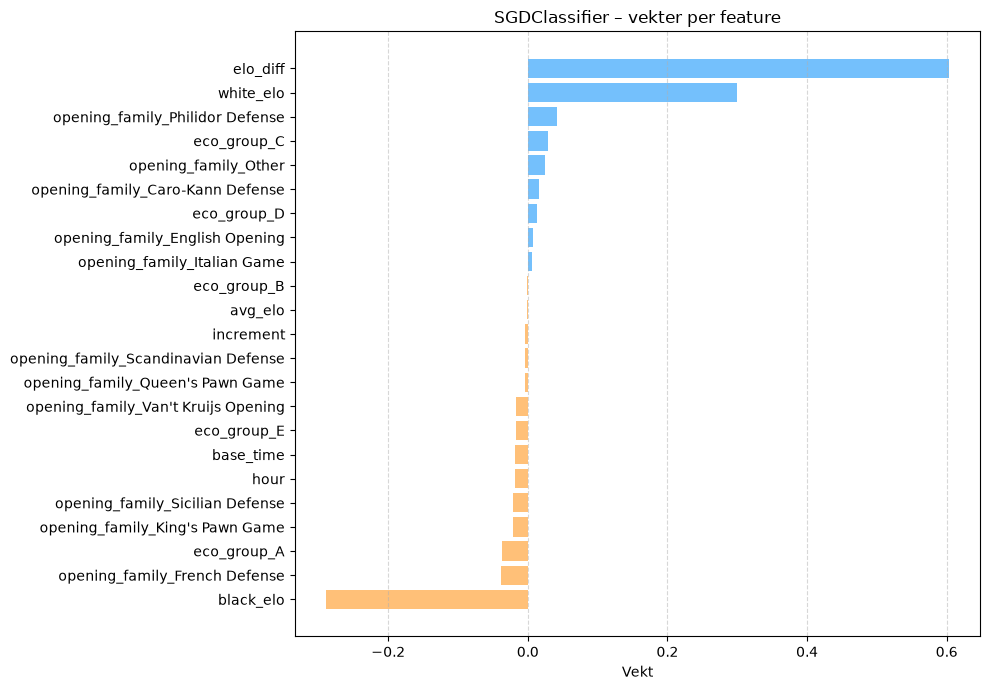

In [65]:
# Vektene til den lineære modellen. Siden alle features er standardisert, kan vi sammenligne størrelsen direkte.
# Positiv vekt = øker sjansen for at hvit vinner, negativ vekt = minsker den.
coefs = pd.Series(sgd_best.coef_[0], index=train_features.columns).sort_values()

plt.figure(figsize=(10, 7))
plt.barh(coefs.index, coefs.values, color=['#ffc078' if v < 0 else '#74c0fc' for v in coefs.values])
plt.title('SGDClassifier – vekter per feature')
plt.xlabel('Vekt')
plt.grid(True, linestyle='--', alpha=0.5, axis='x')
plt.tight_layout()
plt.show()

Den endelige SGDClassifier-modellen får en validerings-accuracy på 0,686 og F1 0,705, akkurat det samme som Elo-baselinen.

Vektene i plottet viser det samme som decision tree: `elo_diff` har den klart største vekten (0,60), og `white_elo` (positiv) og `black_elo` (negativ) peker i samme retning. Åpningene og tidskontrollen har veldig små vekter. Interessant nok har Philidor Defense en positiv vekt og Sicilian Defense en negativ vekt, som passer med EDA-en, men vektene er så små at de nesten ikke påvirker prediksjonene.

## Min egen Logistic Classifier

I forrige prosjekt lagde jeg en egen Linear Classifier som brukte LinearRegression og deretter skalerte prediksjonene til 0–1 med min-max. Den gjorde det klart dårligst, og i oppsummeringen skrev jeg at problemet sannsynligvis var hvordan sannsynlighetene ble beregnet.

Denne gangen prøver jeg å gjøre det riktig, og lager logistisk regresjon helt selv med numpy:

1. Modellen regner ut en score: z = X · w + b
2. Scoren gjøres om til en sannsynlighet med sigmoid-funksjonen: p = 1 / (1 + e^(−z)). Den gir alltid et tall mellom 0 og 1, uansett hvor stor z er.
3. Vektene oppdateres med gradient descent. Gradienten til log loss er (p − y), så hvert steg flytter vektene litt i retningen som gjør feilen mindre.

Forskjellen fra min forrige modell er at sigmoid gir en ekte sannsynlighet for hvert parti, i stedet for å skalere alle prediksjonene ut fra den høyeste og laveste verdien.

In [66]:
class LogisticClassifier(ClassifierMixin, BaseEstimator):

    def __init__(self, learning_rate=0.1, epochs=500):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def _sigmoid(self, z):
        # np.clip hindrer at np.exp får altfor store tall (overflow)
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, x, y):
        x = np.asarray(x, dtype=float)
        y = np.asarray(y, dtype=float)
        n_samples, n_features = x.shape

        self.weights_ = np.zeros(n_features)
        self.bias_ = 0.0
        self.loss_history_ = []
        self.classes_ = np.array([0, 1])

        for _ in range(self.epochs):
            p = self._sigmoid(x @ self.weights_ + self.bias_)

            # Gradient descent: gjennomsnittlig feil (p - y) ganget med input
            self.weights_ -= self.learning_rate * (x.T @ (p - y)) / n_samples
            self.bias_ -= self.learning_rate * np.mean(p - y)

            # Lagrer log loss, slik at jeg kan se om modellen faktisk lærer
            eps = 1e-12
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.loss_history_.append(loss)
        return self

    def predict_proba(self, x):
        p = self._sigmoid(np.asarray(x, dtype=float) @ self.weights_ + self.bias_)
        return np.column_stack([1 - p, p])

    def predict(self, x):
        return (self.predict_proba(x)[:, 1] >= 0.5).astype(int)

In [67]:
lc_default = LogisticClassifier()
lc_default.fit(train_features, train_targets)
validation(lc_default)

Training Accuracy: 0.661 Validation: 0.684
Training Precision: 0.666 Validation: 0.687
Training Recall: 0.689 Validation: 0.712
Training F1: 0.677 Validation: 0.700


learning_rate=0.01: final loss 0.6160, validation accuracy 0.684
learning_rate=0.1: final loss 0.6110, validation accuracy 0.684


learning_rate=0.5: final loss 0.6110, validation accuracy 0.684


learning_rate=1.0: final loss 0.6110, validation accuracy 0.684


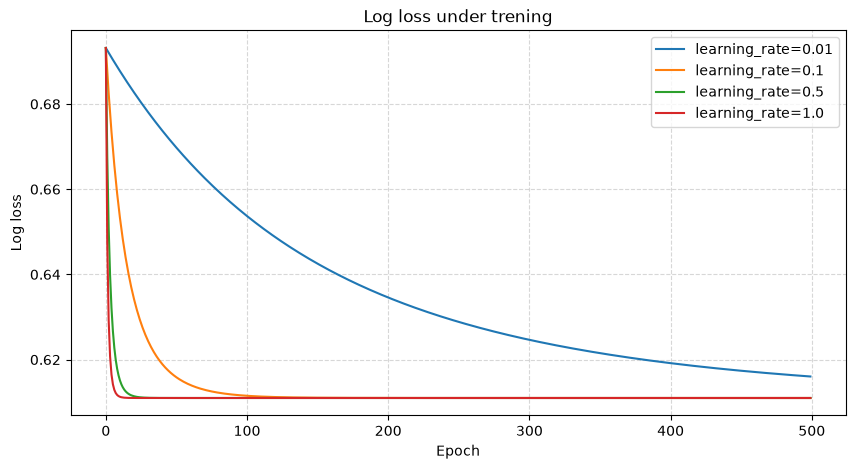

In [68]:
# Tester ulike learning rates og ser hvordan loss utvikler seg
plt.figure(figsize=(10, 5))

for lr in [0.01, 0.1, 0.5, 1.0]:
    model = LogisticClassifier(learning_rate=lr, epochs=500)
    model.fit(train_features, train_targets)
    plt.plot(model.loss_history_, label=f'learning_rate={lr}')
    val_acc = accuracy_score(validation_targets, model.predict(validation_features))
    print(f"learning_rate={lr}: final loss {model.loss_history_[-1]:.4f}, validation accuracy {val_acc:.3f}")

plt.title('Log loss under trening')
plt.xlabel('Epoch')
plt.ylabel('Log loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Alle learning rates ender med samme validerings-accuracy (0,684). Med `learning_rate=0.01` er loss fortsatt litt høyere etter 500 epoker (0,6160), så den har ikke helt konvergert ennå. Med 0,1, 0,5 og 1,0 ender loss på 0,6110, men kurven viser at de høyere verdiene bare kommer dit raskere.

Jeg velger `learning_rate=0.1`. Den når samme loss som de høyere verdiene innen 500 epoker, og en lavere learning rate er tryggere fordi den ikke risikerer å "hoppe over" minimumet.

In [69]:
lc_best = LogisticClassifier(learning_rate=0.1, epochs=500)
lc_best.fit(train_features, train_targets)
print("Selected model: LogisticClassifier, learning_rate=0.1, epochs=500")
validation(lc_best)

Selected model: LogisticClassifier, learning_rate=0.1, epochs=500
Training Accuracy: 0.661 Validation: 0.684
Training Precision: 0.666 Validation: 0.687
Training Recall: 0.689 Validation: 0.712
Training F1: 0.677 Validation: 0.700


In [70]:
# Sammenligner vektene til min egen modell med SGDClassifier.
# Hvis min implementasjon er riktig, burde de peke i samme retning for de viktigste features.
compare_weights = pd.DataFrame({
    'min modell': lc_best.weights_,
    'SGDClassifier': sgd_best.coef_[0],
}, index=train_features.columns)
compare_weights.loc[['elo_diff', 'white_elo', 'black_elo', 'avg_elo', 'base_time', 'increment', 'hour']].round(3)

,min modell,SGDClassifier
elo_diff,0.629,0.603
white_elo,0.298,0.300
black_elo,-0.315,-0.289
avg_elo,-0.017,-0.001
base_time,-0.020,-0.018
increment,-0.025,-0.004
hour,-0.018,-0.019


Min egen logistiske regresjon får en validerings-accuracy på 0,684 og F1 0,700, nesten det samme som SGDClassifier (0,686 og 0,705).

Det viktigste er tabellen over vektene: min modell og SGDClassifier har nesten de samme vektene. `elo_diff` er 0,629 mot 0,603, `white_elo` er 0,298 mot 0,300 og `black_elo` er −0,315 mot −0,289. Det viser at implementasjonen min fungerer, og at den lærer det samme som scikit-learn sin modell.

Sammenlignet med min Linear Classifier fra forrige prosjekt (som fikk 0,42 i accuracy på test) er dette en stor forbedring. Det bekrefter det jeg skrev i forrige oppsummering: problemet var hvordan sannsynlighetene ble regnet ut. Med sigmoid i stedet for min-max-skalering gir modellen fornuftige sannsynligheter.

# EVALUATION

## Confusion Matrices

Confusion matrix viser hvor mange partier modellen klassifiserer riktig og feil for hver klasse:

- **True Positive (TP):** modellen sier hvit vinner, og hvit vant.
- **True Negative (TN):** modellen sier hvit vinner ikke, og hvit vant ikke (svart vant eller remis).
- **False Positive (FP):** modellen sier hvit vinner, men hvit vant ikke.
- **False Negative (FN):** modellen sier hvit vinner ikke, men hvit vant.

Siden klassene er nesten like store denne gangen, forventer jeg at feilene er mer jevnt fordelt enn i forrige prosjekt, der modellene nesten bare gjettet "bestått".

In [71]:
# A function for plotting a confusion matrix for a model on test data
def show_confusion(model, title):
    predictions = model.predict(test_features)
    confusion = confusion_matrix(test_targets, predictions)
    display = ConfusionMatrixDisplay(confusion, display_labels=['Ikke hvit seier', 'Hvit seier'])
    display.plot(cmap='Blues')
    plt.title(title)
    plt.show()

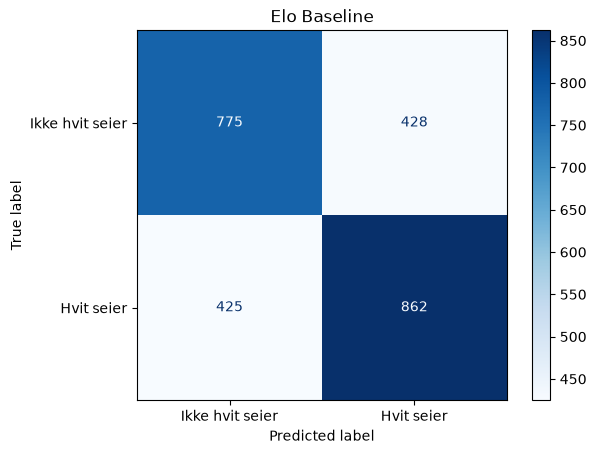

In [72]:
show_confusion(elo_baseline, 'Elo Baseline')

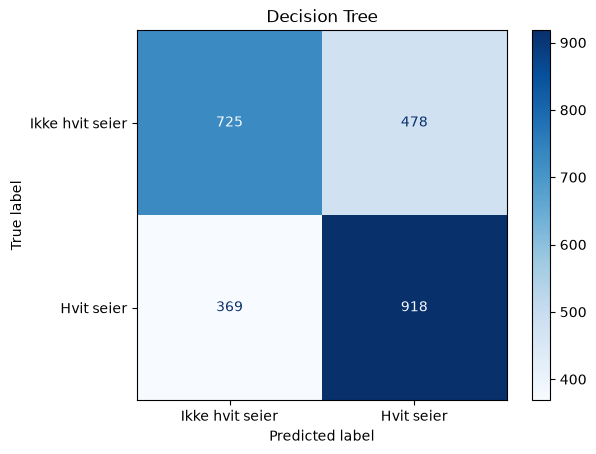

In [73]:
show_confusion(dt_best, 'Decision Tree')

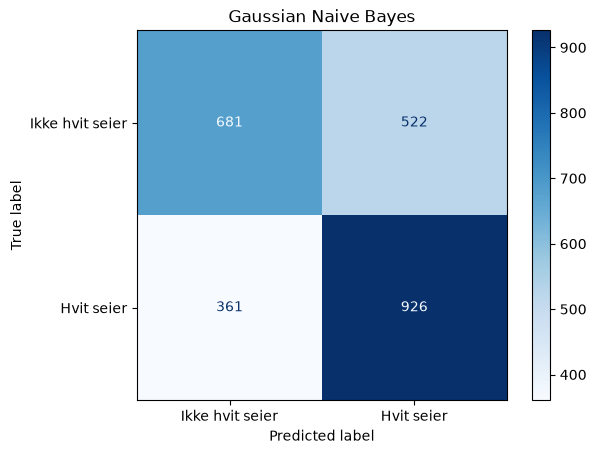

In [74]:
show_confusion(nb_best, 'Gaussian Naive Bayes')

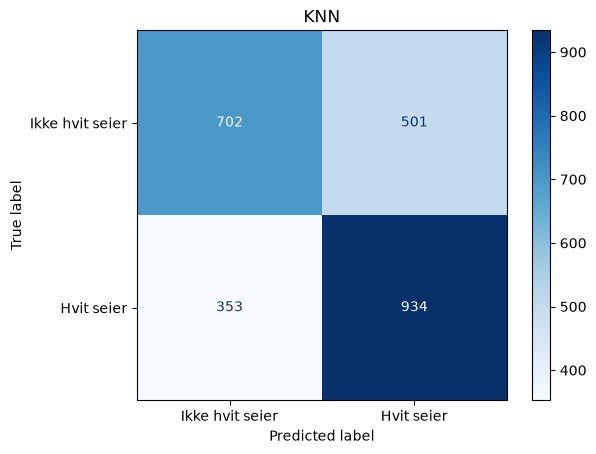

In [75]:
show_confusion(knn_best, 'KNN')

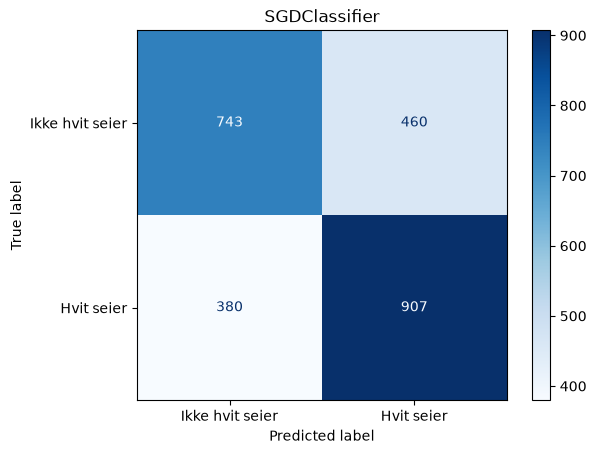

In [76]:
show_confusion(sgd_best, 'SGDClassifier')

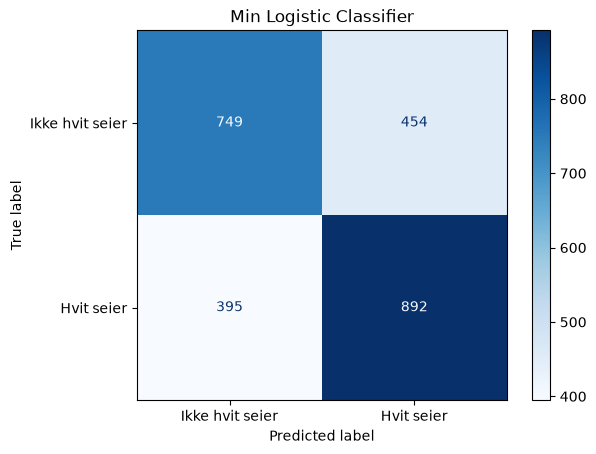

In [77]:
show_confusion(lc_best, 'Min Logistic Classifier')

In [78]:
# Skriver ut tallene fra alle confusion matrices, så det blir lettere å sammenligne
for name, model in [('Elo Baseline', elo_baseline), ('Decision Tree', dt_best), ('Naive Bayes', nb_best),
                    ('KNN', knn_best), ('SGDClassifier', sgd_best), ('Min Logistic', lc_best)]:
    tn, fp, fn, tp = confusion_matrix(test_targets, model.predict(test_features)).ravel()
    print(f"{name:15s}  TP={tp}  TN={tn}  FP={fp}  FN={fn}")

Elo Baseline     TP=862  TN=775  FP=428  FN=425
Decision Tree    TP=918  TN=725  FP=478  FN=369
Naive Bayes      TP=926  TN=681  FP=522  FN=361
KNN              TP=934  TN=702  FP=501  FN=353
SGDClassifier    TP=907  TN=743  FP=460  FN=380
Min Logistic     TP=892  TN=749  FP=454  FN=395


### Confusion matrices for modellene

**Elo Baseline:** TP = 862, TN = 775, FP = 428, FN = 425. Feilene er nesten helt jevnt fordelt mellom de to klassene. Det gir mening, siden baselinen bare ser på hvem som har høyest rating og ikke har noen preferanse for den ene klassen.

**Decision Tree:** TP = 918, TN = 725, FP = 478, FN = 369. Treet gjetter "hvit vinner" litt oftere enn baselinen. Det finner flere av partiene der hvit faktisk vant (918 mot 862), men gjør også flere feil der hvit ikke vant (478 mot 428).

**Gaussian Naive Bayes:** TP = 926, TN = 681, FP = 522, FN = 361. Samme mønster, men enda tydeligere: den har flest falske positive (522) av alle modellene.

**KNN:** TP = 934, TN = 702, FP = 501, FN = 353. Har flest TP, men også mange FP.

**SGDClassifier:** TP = 907, TN = 743, FP = 460, FN = 380. Mer balansert enn treet og KNN.

**Min Logistic Classifier:** TP = 892, TN = 749, FP = 454, FN = 395. Ligner mye på SGDClassifier.

Alle modellene som har lært fra dataene, gjetter "hvit vinner" litt oftere enn Elo-baselinen. Det kan henge sammen med at hvit vinner litt oftere enn svart totalt (51,7 %), så modellene har lært at hvit har en liten fordel. Baselinen vet ikke noe om det, siden den bare ser på ratingen.

Alle modellene over er kun tunet ved hjelp av valideringssettet. Nå trener jeg de valgte modellene på nytt på trenings- og valideringsdataene til sammen, og kjører dem for første og eneste gang på **testsettet**.

In [79]:
trainval_features = pd.concat([train_features, validation_features])
trainval_targets = pd.concat([train_targets, validation_targets])

elo_final = EloBaseline(diff_mean=elo_diff_mean, diff_std=elo_diff_std)
elo_final.fit(trainval_features, trainval_targets)

dt_final = DecisionTreeClassifier(max_depth=4, random_state=13)
dt_final.fit(trainval_features, trainval_targets)

nb_final = GaussianNB(var_smoothing=1)
nb_final.fit(trainval_features, trainval_targets)

knn_final = KNeighborsClassifier(n_neighbors=101)
knn_final.fit(trainval_features, trainval_targets)

sgd_final = SGDClassifier(loss='log_loss', alpha=1e-2, random_state=13)
sgd_final.fit(trainval_features, trainval_targets)

lc_final = LogisticClassifier(learning_rate=0.1, epochs=500)
lc_final.fit(trainval_features, trainval_targets)

print("Alle modellene er trent på trenings- og valideringsdataene")

Alle modellene er trent på trenings- og valideringsdataene


## Final Test Results — All Models

In [80]:
final_models = {
    'Elo Baseline': elo_final,
    'Decision Tree (max_depth=4)': dt_final,
    'Gaussian Naive Bayes (var_smoothing=1)': nb_final,
    'KNN (k=101)': knn_final,
    'SGDClassifier': sgd_final,
    'Min Logistic Classifier': lc_final,
}

results = {}
for name, model in final_models.items():
    print(f"\n")
    print(name)
    results[name] = test(model)



Elo Baseline
Training Accuracy: 0.658 Validation: 0.686 Testing: 0.657
Training Precision: 0.669 Validation: 0.694 Testing: 0.668
Training Recall: 0.668 Validation: 0.700 Testing: 0.670
Training F1: 0.668 Validation: 0.697 Testing: 0.669
Specificity (TNR) - Testing: 0.644
NPV               - Testing: 0.646


Decision Tree (max_depth=4)
Training Accuracy: 0.660 Validation: 0.686 Testing: 0.660
Training Precision: 0.659 Validation: 0.683 Testing: 0.658
Training Recall: 0.710 Validation: 0.733 Testing: 0.713
Training F1: 0.684 Validation: 0.707 Testing: 0.684
Specificity (TNR) - Testing: 0.603
NPV               - Testing: 0.663


Gaussian Naive Bayes (var_smoothing=1)
Training Accuracy: 0.647 Validation: 0.657 Testing: 0.641
Training Precision: 0.643 Validation: 0.651 Testing: 0.638
Training Recall: 0.710 Validation: 0.726 Testing: 0.708
Training F1: 0.675 Validation: 0.686 Testing: 0.671
Specificity (TNR) - Testing: 0.570
NPV               - Testing: 0.646


KNN (k=101)


Training Accuracy: 0.660 Validation: 0.676 Testing: 0.659
Training Precision: 0.657 Validation: 0.672 Testing: 0.653
Training Recall: 0.715 Validation: 0.726 Testing: 0.724
Training F1: 0.684 Validation: 0.698 Testing: 0.687
Specificity (TNR) - Testing: 0.589
NPV               - Testing: 0.666


SGDClassifier
Training Accuracy: 0.658 Validation: 0.687 Testing: 0.661
Training Precision: 0.664 Validation: 0.692 Testing: 0.667
Training Recall: 0.684 Validation: 0.708 Testing: 0.688
Training F1: 0.674 Validation: 0.700 Testing: 0.678
Specificity (TNR) - Testing: 0.633
NPV               - Testing: 0.655


Min Logistic Classifier
Training Accuracy: 0.660 Validation: 0.685 Testing: 0.659
Training Precision: 0.665 Validation: 0.688 Testing: 0.663
Training Recall: 0.688 Validation: 0.715 Testing: 0.691
Training F1: 0.676 Validation: 0.701 Testing: 0.677
Specificity (TNR) - Testing: 0.624
NPV               - Testing: 0.654


In [81]:
# Summary table
results_df = pd.DataFrame(results).T
results_df = results_df.round(3)
results_df

,accuracy,precision,recall,f1,specificity,npv
Elo Baseline,0.657,0.668,0.670,0.669,0.644,0.646
Decision Tree (max_depth=4),0.660,0.658,0.713,0.684,0.603,0.663
Gaussian Naive Bayes (var_smoothing=1),0.641,0.638,0.708,0.671,0.570,0.646
KNN (k=101),0.659,0.653,0.724,0.687,0.589,0.666
SGDClassifier,0.661,0.667,0.688,0.678,0.633,0.655
Min Logistic Classifier,0.659,0.663,0.691,0.677,0.624,0.654


### Endelige testresultater for modellene

**Elo Baseline**

Elo-baselinen får en Testing Accuracy på 0,657 og F1 på 0,669. Merk at valideringsresultatet var 0,686, men testresultatet er 0,657. Siden baselinen ikke lærer noe, viser dette at valideringssettet tilfeldigvis var litt "lettere" enn testsettet. Alle modellene har derfor lavere tall på test enn på validering.

**Decision Tree (max_depth=4)**

Testing Accuracy 0,660, F1 0,684, Recall 0,713. Litt høyere recall enn baselinen, men lavere specificity (0,603 mot 0,644).

**Gaussian Naive Bayes (var_smoothing=1)**

Testing Accuracy 0,641, F1 0,671. Den svakeste modellen, og den eneste som er tydelig dårligere enn baselinen. Den har også lavest specificity (0,570).

**KNN (k=101)**

Testing Accuracy 0,659, F1 0,687. Den høyeste F1-scoren og recall (0,724), men lav specificity (0,589).

**SGDClassifier**

Testing Accuracy 0,661, F1 0,678. Den høyeste accuracyen, med en god balanse mellom precision (0,667) og recall (0,688), og den høyeste specificityen av de lærte modellene (0,633).

**Min Logistic Classifier**

Testing Accuracy 0,659, F1 0,677. Nesten identisk med SGDClassifier, som forventet siden de er samme type modell.

### Sammenligning av modellene

Det viktigste funnet er at **ingen av modellene slår Elo-baselinen med mer enn noen få tideler**. SGDClassifier har den høyeste accuracyen (0,661), mot 0,657 for baselinen. Det er bare 0,4 prosentpoeng, rundt 10 partier av 2490. Den forskjellen er så liten at den like gjerne kan være tilfeldig.

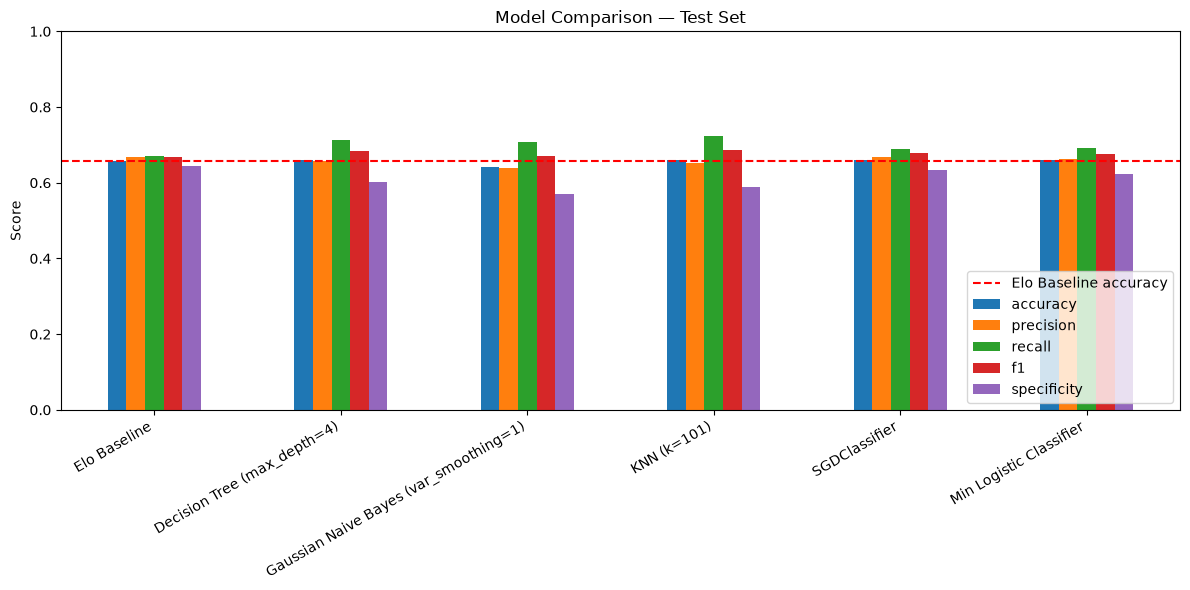

In [82]:
# Bar chart som sammenligner alle modellene
results_df[['accuracy', 'precision', 'recall', 'f1', 'specificity']].plot(kind='bar', figsize=(12, 6))
plt.title('Model Comparison — Test Set')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1.0)
plt.axhline(results_df.loc['Elo Baseline', 'accuracy'], color='red', linestyle='--', label='Elo Baseline accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

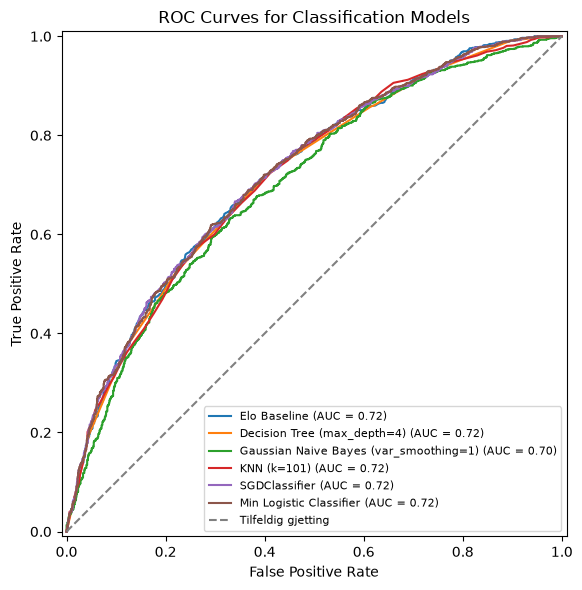

In [83]:
fig, ax = plt.subplots(figsize=(9, 6))

for name, model in final_models.items():
    RocCurveDisplay.from_estimator(model, test_features, test_targets, name=name, ax=ax)

plt.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Tilfeldig gjetting')
plt.title("ROC Curves for Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

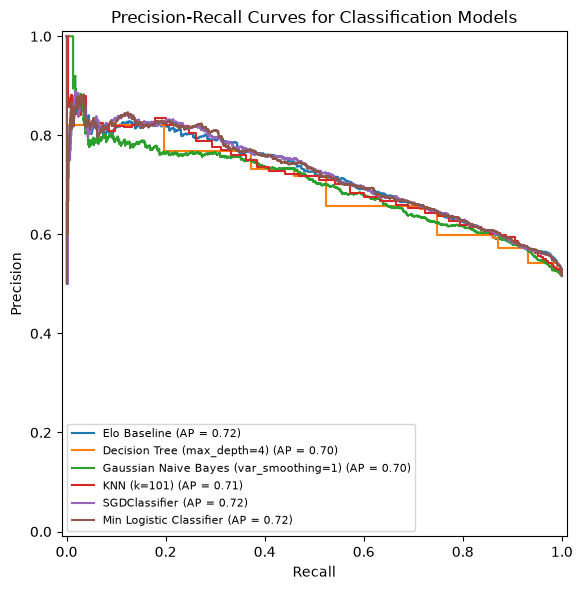

In [84]:
fig, ax = plt.subplots(figsize=(9, 6))

for name, model in final_models.items():
    PrecisionRecallDisplay.from_estimator(model, test_features, test_targets, name=name, ax=ax)

plt.title("Precision-Recall Curves for Classification Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [85]:
# Henter ut AUC og AP som tall, så jeg kan skrive dem i konklusjonen
from sklearn.metrics import roc_auc_score, average_precision_score

for name, model in final_models.items():
    proba = model.predict_proba(test_features)[:, 1]
    print(f"{name:45s} AUC: {roc_auc_score(test_targets, proba):.3f}  AP: {average_precision_score(test_targets, proba):.3f}")

Elo Baseline                                  AUC: 0.722  AP: 0.717
Decision Tree (max_depth=4)                   AUC: 0.717  AP: 0.699
Gaussian Naive Bayes (var_smoothing=1)        AUC: 0.702  AP: 0.699
KNN (k=101)                                   AUC: 0.718  AP: 0.712
SGDClassifier                                 AUC: 0.723  AP: 0.721
Min Logistic Classifier                       AUC: 0.723  AP: 0.720


### ROC og Precision-Recall

**ROC (AUC):** SGDClassifier og min Logistic Classifier har den høyeste AUC-scoren (0,723), rett foran Elo-baselinen (0,722). KNN får 0,718, Decision Tree 0,717 og Gaussian Naive Bayes 0,702. Alle kurvene ligger nesten oppå hverandre, bortsett fra Naive Bayes, som er litt lavere.

**Precision-Recall (AP):** Samme bilde. SGDClassifier (0,721), min Logistic Classifier (0,720) og Elo-baselinen (0,717) er best, mens Decision Tree og Naive Bayes ligger på 0,699.

En AUC på rundt 0,72 betyr at hvis vi tar ett parti hvit vant og ett parti hvit ikke vant, vil modellen gi høyest sannsynlighet til det riktige partiet i 72 % av tilfellene. Det er godt over tilfeldig gjetting (0,50), men langt unna perfekt.

I forrige prosjekt fikk SGDClassifier en AUC på 0,97. At det er så mye lavere her, handler ikke om at modellene er dårligere, men om at sjakkresultater er mye mer tilfeldige enn eksamensresultater. Studietid forklarte nesten alt der (r = 0,83), mens ratingforskjellen her bare har r = 0,38.

Oppsummering av prosjektet

Hva jeg gjorde: Jeg brukte 20 000 partier fra Lichess for å prøve å forutsi om hvit vinner et sjakkparti, bare basert på informasjon som finnes før partiet starter: ratingen til spillerne, tidskontrollen, tidspunktet og åpningen.

Det jeg fant i EDA-en: Ratingforskjellen mellom spillerne er det eneste som virkelig betyr noe (r = 0,38). Hvit vinner 14 % når hvit er mye svakere, og 86 % når hvit er mye sterkere. Elo-formelen beskriver dette ganske godt, men den svakere spilleren gjør det litt bedre enn formelen forventer. Tidskontroll og tidspunkt har nesten ingen sammenheng med resultatet. Noen åpninger ser ut til å henge sammen med flere hvite seire, men det er usikkert om det er åpningen eller spillerne som forklarer det.

Jeg fant også flere kolonner som ville vært data leakage: ratingendringen, antall trekk og hvordan partiet endte. Ratingendringen viste nesten svaret direkte (alltid ≥ 0 når hvit vant), så den måtte fjernes.

Preprocessing: Jeg fjernet correspondence-partiene og partiene uten rating (under 0,5 % av dataene), og laget en binær target: hvit vinner eller ikke. Remis var bare 3,4 %, så det ga ikke mening med tre klasser. Jeg laget nye features (`elo_diff`, `avg_elo`, `eco_group`), forenklet åpningene til de 10 vanligste + `Other`, og brukte one-hot encoding. Jeg delte dataene med stratification, og fant de vanligste åpningene, gjennomsnittet og standardavviket kun fra treningsdataene. Jeg brukte også `reindex` slik at alle settene fikk de samme kolonnene, og `.loc` i stedet for `.iloc` siden indeksen hadde hull etter at rader var fjernet.

Modellene jeg testet, og hvorfor de endte opp som de gjorde:

Elo-baseline – ingen læring, gjetter bare at den med høyest rating vinner. Den var overraskende vanskelig å slå.

Decision Tree – overfittet helt uten begrensning (1,00 på trening, 0,59 på validering). Med `max_depth=4` brukte treet `elo_diff` til 97,8 % av beslutningene, så det lærte i praksis samme regel som baselinen.

Naive Bayes – den svakeste modellen. Antagelsen om at features er uavhengige stemmer dårlig her, siden flere av ratingkolonnene er laget av hverandre.

KNN – trengte veldig mange naboer (k=101) for å bli stabil, fordi enkeltpartier er så tilfeldige.

SGDClassifier – trengte sterkere regularisering (`alpha=0.01`) enn standarden, slik at den ikke la vekt på små og tilfeldige sammenhenger. Endte med høyest accuracy og AUC.

Min egen Logistic Classifier – fikk nesten de samme vektene og resultatene som SGDClassifier. Det viser at implementasjonen fungerer, og det er en stor forbedring fra Linear Classifier-en i forrige prosjekt (0,42 i accuracy). Problemet den gang var min-max-skaleringen av sannsynlighetene, og med sigmoid fungerer det.

Sluttresultater på testsettet:

| Modell | Accuracy | F1 | Specificity | AUC |
|---|---|---|---|---|
| Elo Baseline | 0,657 | 0,669 | 0,644 | 0,722 |
| Decision Tree (max_depth=4) | 0,660 | 0,684 | 0,603 | 0,717 |
| Gaussian Naive Bayes | 0,641 | 0,671 | 0,570 | 0,702 |
| KNN (k=101) | 0,659 | 0,687 | 0,589 | 0,718 |
| SGDClassifier | 0,661 | 0,678 | 0,633 | 0,723 |
| Min Logistic Classifier | 0,659 | 0,677 | 0,624 | 0,723 |

Det viktigste funnet: Alle modellene havner på rundt 66 % accuracy, akkurat som Elo-baselinen. Maskinlæring klarte ikke å finne noe vesentlig mer i dataene enn det Elo-systemet allerede vet. Det betyr ikke at modellene er dårlige. Det betyr at ratingen allerede inneholder nesten all informasjonen som finnes før et parti starter, og at resten avgjøres av hva som skjer på brettet.

Det er egentlig et ganske bra resultat for Elo-systemet. Hele poenget med en rating er å forutsi resultater, og det gjør den nesten like godt som modeller som har lært fra 15 000 partier.

Konklusjon: Jeg velger SGDClassifier med `loss='log_loss'` og `alpha=0.01` som den endelige modellen. Den har den høyeste accuracyen (0,661) og AUC (0,723), og den beste balansen mellom precision og recall av de lærte modellene. Men forskjellen fra Elo-baselinen er så liten at jeg ikke kan si at den er bedre i praksis.

Hvis jeg skulle jobbe videre med prosjektet, ville jeg prøvd å legge til informasjon som Elo ikke har: for eksempel hvor mange partier spilleren har spilt (nye spillere har usikker rating), hvordan spilleren har gjort det i de siste partiene, eller om spilleren pleier å vinne eller tape på tid. Det kunne kanskje gitt modellen noe ekstra å jobbe med.